# Face Recognition on Archive(2) — Eigenfaces and Fisherfaces

Closed-set evaluation on identities `s1` through `s38`.

- Training/gallery: images `1.png` through `8.png` per identity.
- Testing: images `9.png` and `10.png` per identity.
- Expected totals: 304 training images, 76 test images, 38 identities.
- `s39` and `s40` are excluded.
- Methods: Eigenfaces (PCA) and Fisherfaces (PCA + LDA).
- Implementation: NumPy and SciPy;

## Cell 1: CELL 1 : setup & config


In [1]:
# ===== SETUP AND CONFIGURATION ======================================
import os
import math
from pathlib import Path
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
WORK = Path(os.environ.get("FACE_WORK", "/kaggle/working"))
WORK.mkdir(parents=True, exist_ok=True)
FACE_SIZE=(60,80)
SHAPE=(FACE_SIZE[1],FACE_SIZE[0])
EIGEN_VAR = 0.95
EIGEN_MAX = 300
EIGEN_DROP_FIRST = 3
FISHER_PCA = 300
FISHER_DIM = 200
FISHER_RIDGE = 1e-2

## Cell 2: CELL 2 : dataset discovery, AUDIT and CLEANING


In [4]:

# ===== DATASET PATH AND FIXED SPLIT ================================

# Find the dataset in the current GitHub Codespace repository.
BASE_DIR = Path.cwd()

candidates = [
    BASE_DIR / "dataset",
    BASE_DIR / "Dataset",
    Path("/drive/notebooks/Archive(2) image png from i1 to 11/")
    # The above path ^^^ needs to be adjusted according to the programmer's system's/cloud's own path. Not doing so may result in FileNotFoundError
]

FOLDER = None

for base in candidates:
    if not base.is_dir():
        continue

    # Check whether subject folders s1 to s38 exist.
    if all((base / f"s{i}").is_dir() for i in range(1, 39)):
        FOLDER = base
        break

    # Also search inside the dataset folder for a nested dataset.
    for subfolder in base.rglob("s1"):
        possible_folder = subfolder.parent

        if all((possible_folder / f"s{i}").is_dir()
               for i in range(1, 39)):
            FOLDER = possible_folder
            break

    if FOLDER is not None:
        break

if FOLDER is None:
    raise FileNotFoundError(
        f"Dataset not found. Current directory: {BASE_DIR}"
    )

folderZ = FOLDER

TARGET_PEOPLE = [f"s{i}" for i in range(1, 39)]
TARGET_SET = set(TARGET_PEOPLE)

missing = [
    person for person in TARGET_PEOPLE
    if not (FOLDER / person).is_dir()
]

if missing:
    raise FileNotFoundError(f"Missing subject folders: {missing}")

print("Dataset:", FOLDER)
print("Identities:", len(TARGET_PEOPLE))


Dataset: /drive/notebooks/Archive(2) image png from i1 to 11
Identities: 38


## Cell 3: fixed train/test split

In [ ]:
# ===== BUILD FIXED TRAIN/TEST SPLIT ================================
# Training: images 1-8
GAL_ITEMS = [(str(folderZ / person / f"{n}.png"), person) for person in TARGET_PEOPLE for n in range(1, 9)]
# Testing: images 9-10
TEST_ITEMS = [(str(folderZ / person / f"{n}.png"), person) for person in TARGET_PEOPLE for n in (9, 10)]
# Verify all required files exist.
missing = [path for path, _ in GAL_ITEMS + TEST_ITEMS if not Path(path).is_file()]
if missing:
    raise FileNotFoundError(f"Missing {len(missing)} images.")
GAL_LABELS = np.array([person for _, person in GAL_ITEMS])
TEST_LABELS = np.array([person for _, person in TEST_ITEMS])
print("Fixed split successfully created.")
print("Identities:", len(TARGET_PEOPLE))
print("Training images:", len(GAL_ITEMS))
print("Testing images:", len(TEST_ITEMS))

Fixed split successfully created.
,Identities: 38
,Training images: 304
,Testing images: 76


## Cell 4: image processing and evaluation utilities

In [ ]:
# ===== IMAGE PROCESSING, GALLERY AND EVALUATION =====================
def item_gray(item):
    with Image.open(item[0]) as image:
        return ImageOps.exif_transpose(image).convert("L")
def gray_to_vec(image):
    gray = image.resize(FACE_SIZE, Image.Resampling.LANCZOS)
    gray = ImageOps.equalize(gray)
    vector = np.asarray(gray).reshape(-1) / 255.0
    return (vector - vector.mean()) / (vector.std() + 1e-6)
def build_matrix(items):
    return np.stack([gray_to_vec(item_gray(item)) for item in items],axis=1)
def unit_rows(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norms, 1e-8)
def make_gallery(features, labels, items):
    return {"feat": features,"labels": np.asarray(labels),"items": items,"people": np.unique(labels)}
RESULTS, METHODS = {}, {}
def evaluate_method(name, gallery, query_features):
    # Similarity between every test image and every gallery image.
    image_scores = query_features @ gallery["feat"].T
    people = gallery["people"]
    n_queries = len(query_features)
    person_scores = np.full((n_queries, len(people)), -np.inf)
    best_gallery_idx = np.zeros((n_queries, len(people)))
    # Give each identity its best gallery-image similarity.
    for j, person in enumerate(people):
        indices = np.flatnonzero(gallery["labels"] == person)
        local_best = np.argmax(image_scores[:, indices], axis=1)
        chosen = indices[local_best]
        person_scores[:, j] = image_scores[np.arange(n_queries), chosen]
        best_gallery_idx[:, j] = chosen
    order = np.argsort(-person_scores, axis=1)
    predictions = people[order[:, 0]]
    correct = predictions == TEST_LABELS
    top5 = np.array([TEST_LABELS[i] in people[order[i, :min(5, len(people))]]
        for i in range(n_queries)])
    rows = np.arange(n_queries)
    predicted_gallery_idx = best_gallery_idx[rows, order[:, 0]]
    top1_scores = person_scores[rows, order[:, 0]]
    result = {
        "top1": float(correct.mean()),
        "top5": float(top5.mean()),
        "correct1": correct,
        "s1": top1_scores,
        "pred_idx": predicted_gallery_idx,
        "predictions": predictions,
        "n_test": n_queries,
        "n_correct": int(correct.sum()),
        "_gal": gallery,
        "_Qk": query_features,
    }
    RESULTS[name] = result
    print(f"\n[{name}]")
    print(f"Rank-1: {result['n_correct']}/{n_queries} = {result['top1']:.2%}")
    print(f"Top-1 errors: {n_queries - result['n_correct']}")
    print(f"Top-5 diagnostic: {result['top5']:.2%}")
    return result
def image_number(path):
    return int(Path(path).stem)

def show_faces(vectors, titles, suptitle=None, ncols=6):
    n = len(vectors)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.8 * ncols, 2.4 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, v, t in zip(axes.ravel(), vectors, titles):
        img = np.asarray(v).reshape(SHAPE)
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
        ax.imshow(img, cmap="gray")
        ax.set_title(t, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


XG = build_matrix(GAL_ITEMS)
XK = build_matrix(TEST_ITEMS)
print("Gallery matrix:", XG.shape)
print("Test matrix:", XK.shape)

Gallery matrix: (4800, 304)
,Test matrix: (4800, 76)


## Block 1: Eigenfaces (PCA)

EIGENFACES
,Eigenface components retained: 155
,Variance explained by first 158: 95.06%
,
,[Eigenfaces]
,Rank-1: 72/76 = 94.74%
,Top-1 errors: 4
,Top-5 diagnostic: 97.37%


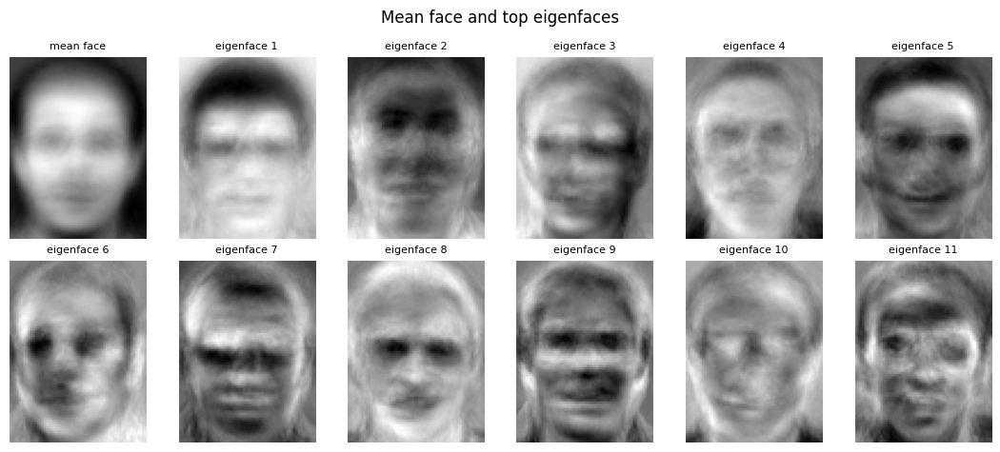

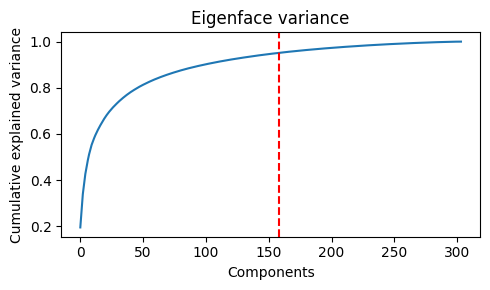

In [ ]:
# ===== BLOCK 1: EIGENFACES (PCA) ===================================
print("EIGENFACES")

MEAN = XG.mean(axis=1, keepdims=True)

XGc = XG - MEAN

# the sample Gram matrix is 304x304, not 4800x4800.
gram = (XGc.T @ XGc)

evals, sample_vecs = np.linalg.eigh(gram)

order = np.argsort(evals)[::-1]

evals = np.clip(evals[order], 0, None)

sample_vecs = sample_vecs[:, order]

# Convert sample-space eigenvectors into normalized pixel-space eigenfaces.

positive = evals > max(evals[0] * 1e-10, 1e-12)
evals = evals[positive]

sample_vecs = sample_vecs[:, positive]
if len(evals) == 0:
    raise ValueError("PCA found no positive eigenvalues. Check the training images.")

evecs = (XGc @ sample_vecs) / np.sqrt(evals)[None, :]

cumvar = np.cumsum(evals) / evals.sum()

K_EIG = min(max(np.searchsorted(cumvar, EIGEN_VAR) + 1, 50),EIGEN_MAX,evecs.shape[1])

U_EIG = evecs[:, EIGEN_DROP_FIRST:K_EIG]

if U_EIG.shape[1] == 0:
    raise ValueError("No Eigenfaces remain after dropping leading components.")
    
print(f"Eigenface components retained: {U_EIG.shape[1]}")
print(f"Variance explained by first {K_EIG}: {cumvar[K_EIG - 1]:.2%}")

def eig_encode(X):
    return unit_rows((U_EIG.T @ (X - MEAN)).T)

METHODS["Eigenfaces"] = {"gal": make_gallery(eig_encode(XG), GAL_LABELS, GAL_ITEMS),"encode": lambda rgb: eig_encode(gray_to_vec(rgb)[:, None])}

evaluate_method("Eigenfaces",METHODS["Eigenfaces"]["gal"],eig_encode(XK))

show_faces([MEAN[:, 0]] + [evecs[:, i] for i in range(min(11, evecs.shape[1]))],
    ["mean face"] + [f"eigenface {i + 1}" for i in range(min(11, evecs.shape[1]))],suptitle="Mean face and top eigenfaces")

plt.figure(figsize=(5, 3))
plt.plot(cumvar)
plt.axvline(K_EIG, color="r", linestyle="--")
plt.xlabel("Components")
plt.ylabel("Cumulative explained variance")
plt.title("Eigenface variance")
plt.tight_layout()
plt.show()


## Block 2: Fisherfaces (PCA + LDA)

FISHERFACES
,PCA dimensions: 300
,Fisherface components: 37
,Top Fisher criteria: [982.933 840.408 721.602 412.236 382.488]
,
,[Fisherfaces]
,Rank-1: 74/76 = 97.37%
,Top-1 errors: 2
,Top-5 diagnostic: 100.00%


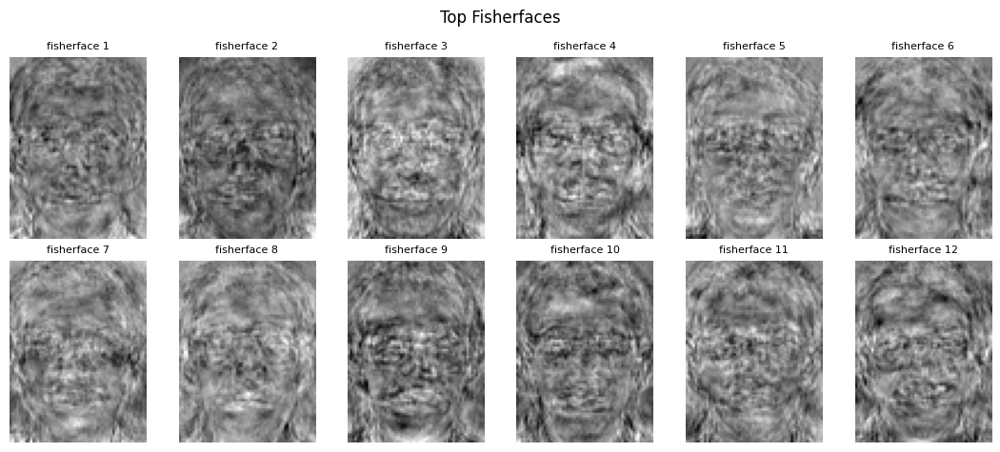

In [ ]:
# ===== BLOCK 2: FISHERFACES (PCA + LDA) =============================
print("FISHERFACES")

# PCA-reduced training data.
p = min(FISHER_PCA, evecs.shape[1])

P = evecs[:, :p]

Y = (P.T @ XGc).T

people, class_id = np.unique(GAL_LABELS, return_inverse=True)

class_count = len(people)

counts = np.bincount(class_id)

class_means = np.zeros((class_count, p),)

np.add.at(class_means, class_id, Y)
class_means /= counts[:, None]

global_mean = Y.mean(axis=0)

within_centered = Y - class_means[class_id]

Sw = within_centered.T @ within_centered

mean_offsets = class_means - global_mean
Sb = (mean_offsets * counts[:, None]).T @ mean_offsets

# Regularize within-class scatter before the generalized eigenproblem.
ridge = FISHER_RIDGE * np.trace(Sw) / p
Sw += np.eye(p, dtype=np.float64) * ridge

values, vectors = scipy.linalg.eigh(Sb, Sw)

order = np.argsort(values)[::-1]

NF = min(class_count - 1, p, FISHER_DIM)

W_FISH = (P @ vectors[:, order[:NF]]).astype(np.float32)

print(f"PCA dimensions: {p}")
print(f"Fisherface components: {NF}")
print(f"Top Fisher criteria: {np.round(values[order[:5]], 3)}")


def fish_encode(X):
    return unit_rows((W_FISH.T @ (X - MEAN)).T)


METHODS["Fisherfaces"] = {"gal": make_gallery(fish_encode(XG), GAL_LABELS, GAL_ITEMS),"encode": lambda rgb: fish_encode(rgb_to_vec(rgb)[:, None])}

evaluate_method("Fisherfaces",METHODS["Fisherfaces"]["gal"],fish_encode(XK))

show_faces([W_FISH[:, i] for i in range(min(12, NF))],[f"fisherface {i + 1}" for i in range(min(12, NF))],suptitle="Top Fisherfaces")



## Final summary and saved predictions\


,===========================================================================
,Eigenfaces: TOP-5 RESULTS FOR ALL 76 TEST IMAGES
,===========================================================================
,Test 01/76 | True: s1 | Selected: s1 | CORRECT | Top-1 similarity: 0.5572 | Top-5: s1, s33, s6, s23, s13
,Test 02/76 | True: s1 | Selected: s17 | WRONG | Top-1 similarity: 0.5402 | Top-5: s17, s16, s25, s4, s9


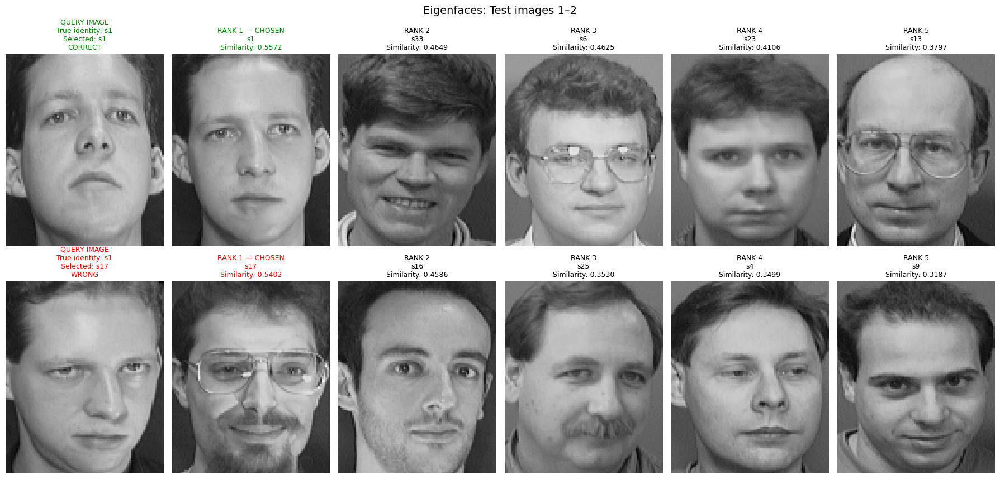

Test 03/76 | True: s2 | Selected: s2 | CORRECT | Top-1 similarity: 0.7771 | Top-5: s2, s32, s1, s11, s15
,Test 04/76 | True: s2 | Selected: s2 | CORRECT | Top-1 similarity: 0.8632 | Top-5: s2, s15, s1, s10, s24


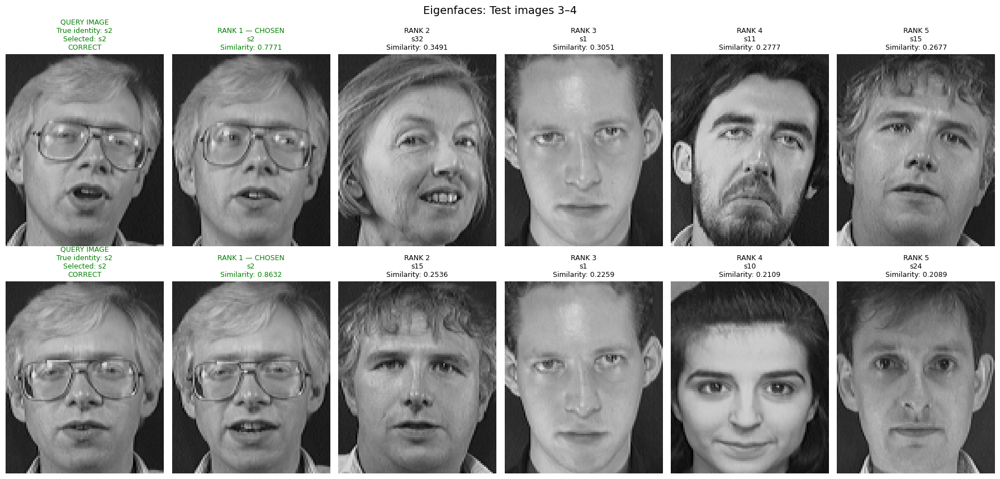

Test 05/76 | True: s3 | Selected: s3 | CORRECT | Top-1 similarity: 0.6782 | Top-5: s3, s4, s25, s20, s31
,Test 06/76 | True: s3 | Selected: s3 | CORRECT | Top-1 similarity: 0.7344 | Top-5: s3, s4, s20, s25, s30


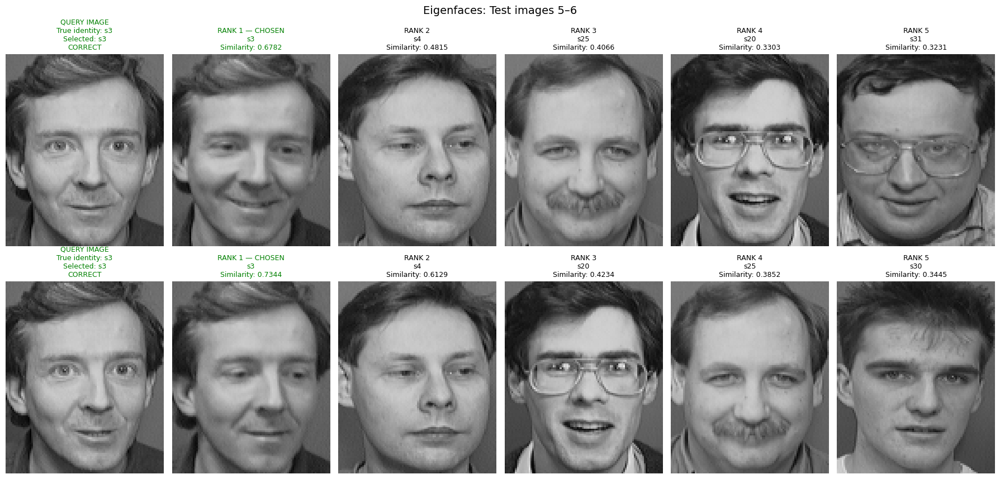

Test 07/76 | True: s4 | Selected: s4 | CORRECT | Top-1 similarity: 0.8566 | Top-5: s4, s25, s17, s27, s20
,Test 08/76 | True: s4 | Selected: s4 | CORRECT | Top-1 similarity: 0.8102 | Top-5: s4, s25, s18, s26, s3


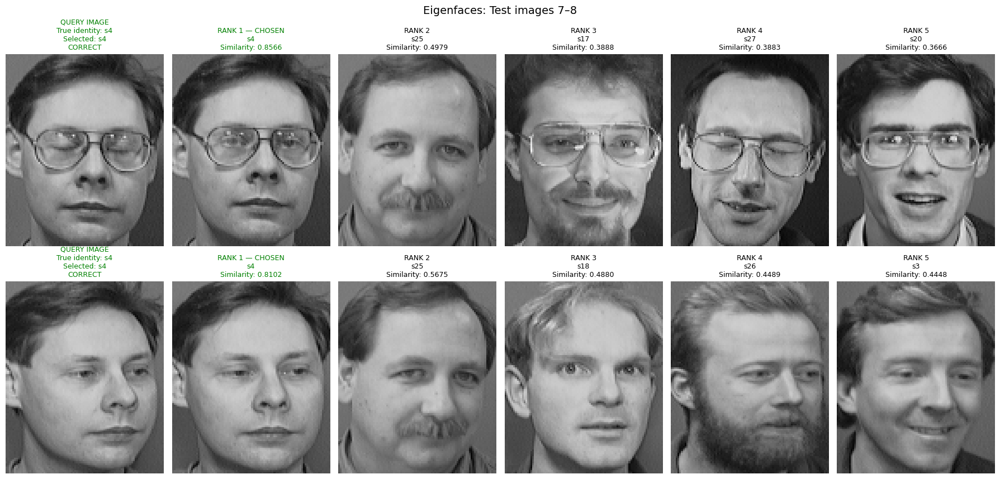

Test 09/76 | True: s5 | Selected: s5 | CORRECT | Top-1 similarity: 0.8131 | Top-5: s5, s21, s30, s9, s17
,Test 10/76 | True: s5 | Selected: s36 | WRONG | Top-1 similarity: 0.5042 | Top-5: s36, s18, s11, s8, s15


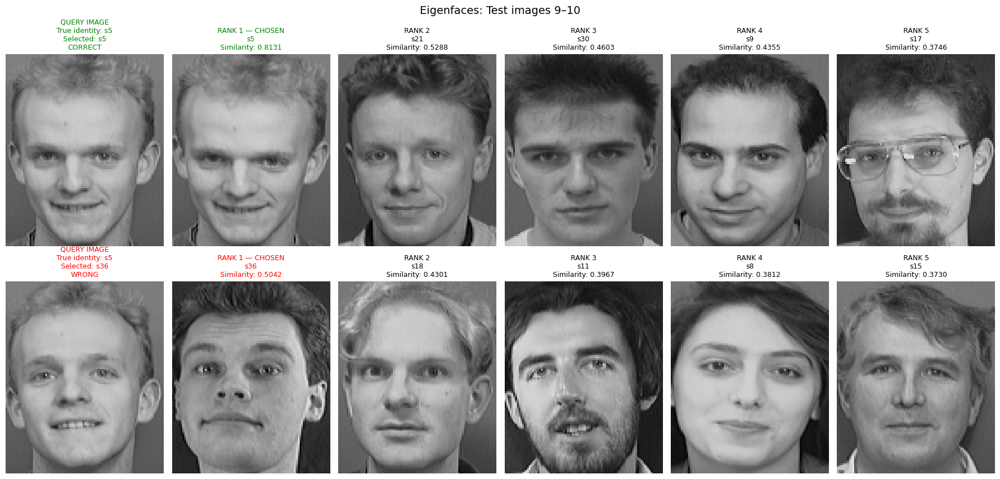

Test 11/76 | True: s6 | Selected: s6 | CORRECT | Top-1 similarity: 0.7353 | Top-5: s6, s23, s38, s29, s1
,Test 12/76 | True: s6 | Selected: s6 | CORRECT | Top-1 similarity: 0.9326 | Top-5: s6, s23, s14, s10, s28


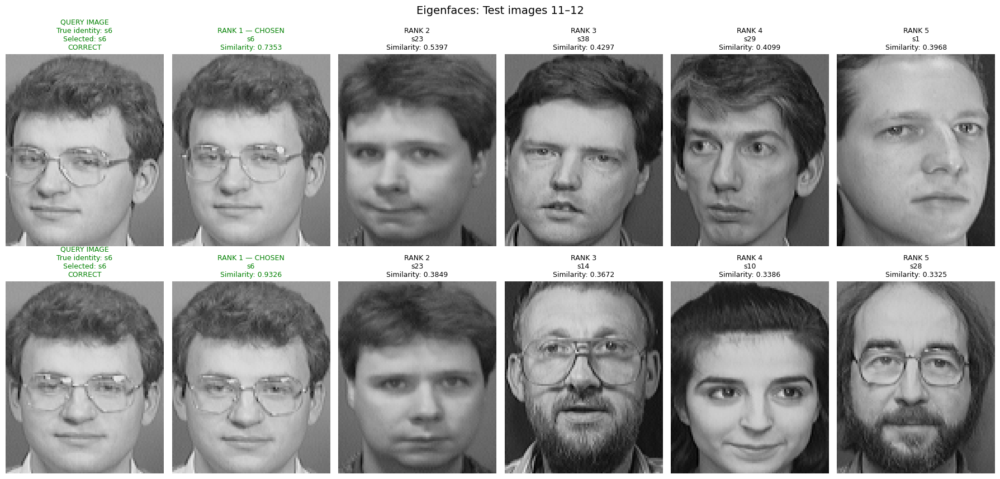

Test 13/76 | True: s7 | Selected: s7 | CORRECT | Top-1 similarity: 0.8586 | Top-5: s7, s23, s29, s36, s8
,Test 14/76 | True: s7 | Selected: s7 | CORRECT | Top-1 similarity: 0.7752 | Top-5: s7, s36, s5, s21, s32


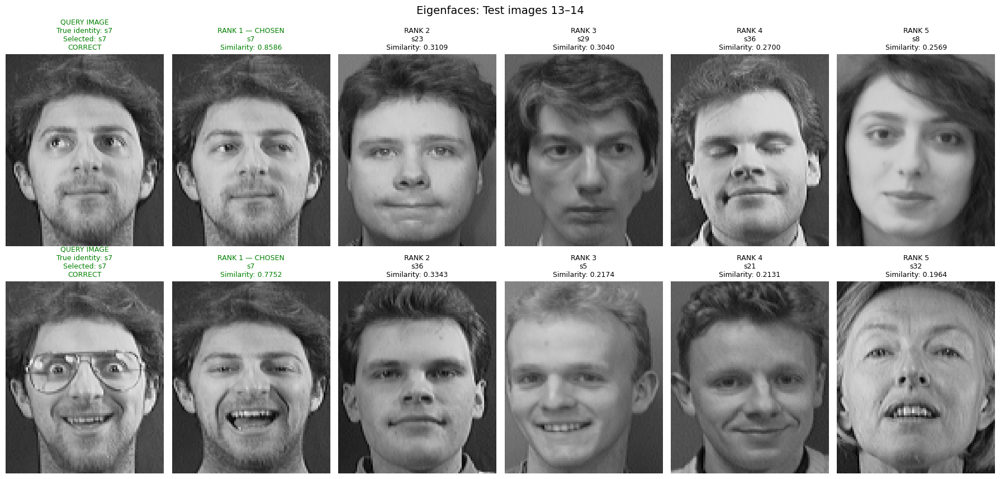

Test 15/76 | True: s8 | Selected: s8 | CORRECT | Top-1 similarity: 0.8088 | Top-5: s8, s11, s24, s18, s1
,Test 16/76 | True: s8 | Selected: s8 | CORRECT | Top-1 similarity: 0.8156 | Top-5: s8, s11, s4, s35, s2


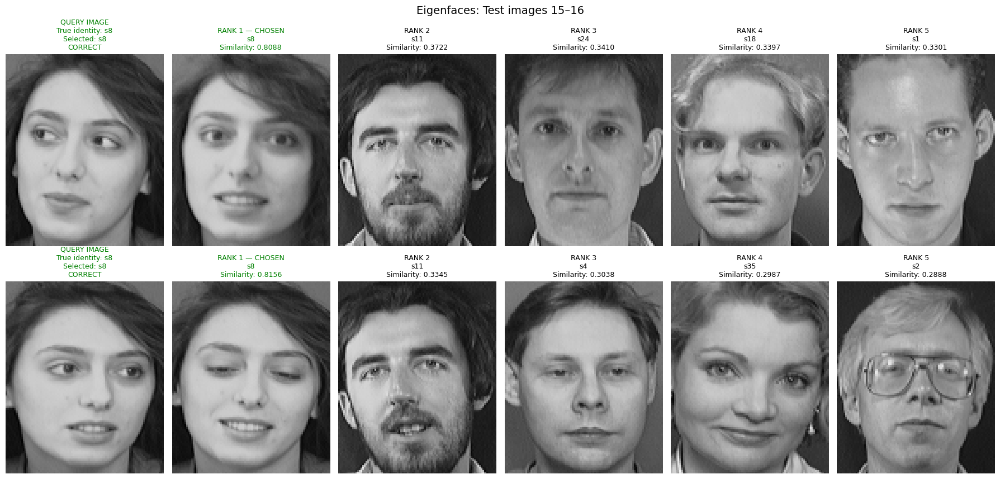

Test 17/76 | True: s9 | Selected: s9 | CORRECT | Top-1 similarity: 0.7722 | Top-5: s9, s31, s25, s5, s17
,Test 18/76 | True: s9 | Selected: s9 | CORRECT | Top-1 similarity: 0.7336 | Top-5: s9, s4, s26, s17, s31


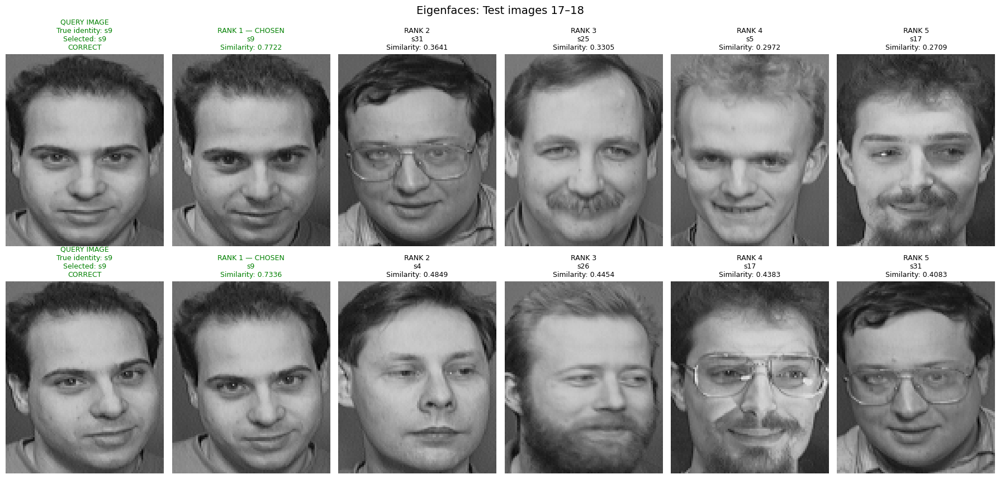

Test 19/76 | True: s10 | Selected: s10 | CORRECT | Top-1 similarity: 0.5994 | Top-5: s10, s8, s19, s29, s5
,Test 20/76 | True: s10 | Selected: s8 | WRONG | Top-1 similarity: 0.6126 | Top-5: s8, s18, s4, s11, s10


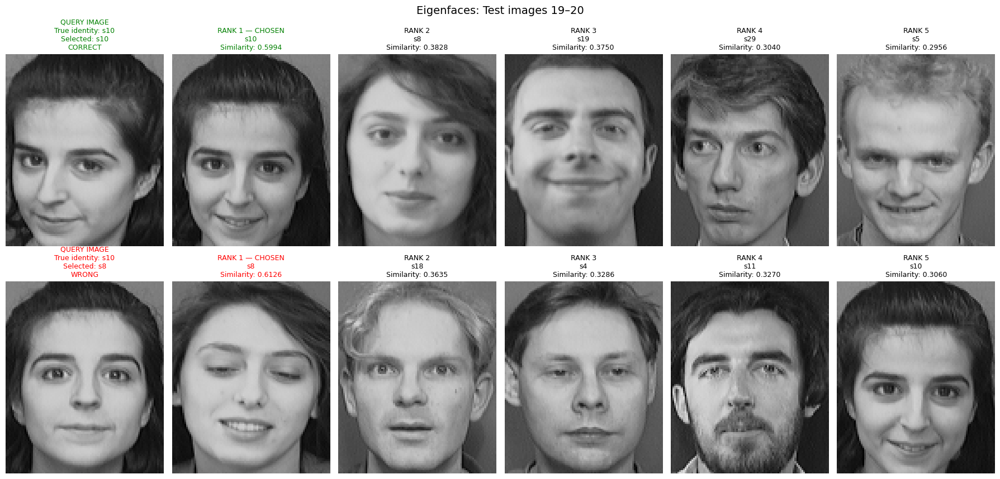

Test 21/76 | True: s11 | Selected: s11 | CORRECT | Top-1 similarity: 0.8587 | Top-5: s11, s38, s8, s4, s15
,Test 22/76 | True: s11 | Selected: s11 | CORRECT | Top-1 similarity: 0.8192 | Top-5: s11, s38, s20, s4, s8


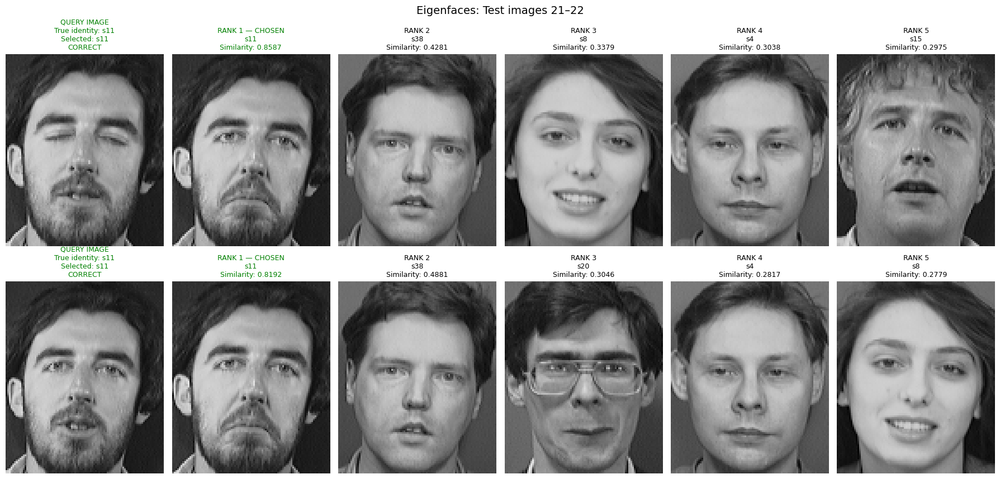

Test 23/76 | True: s12 | Selected: s12 | CORRECT | Top-1 similarity: 0.6858 | Top-5: s12, s10, s9, s2, s32
,Test 24/76 | True: s12 | Selected: s12 | CORRECT | Top-1 similarity: 0.7284 | Top-5: s12, s30, s9, s10, s27


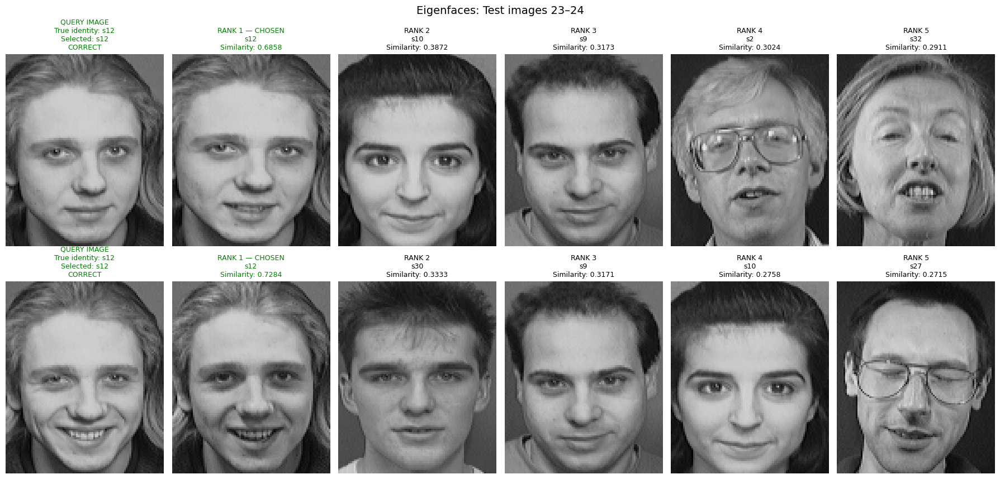

Test 25/76 | True: s13 | Selected: s13 | CORRECT | Top-1 similarity: 0.4816 | Top-5: s13, s30, s1, s33, s16
,Test 26/76 | True: s13 | Selected: s13 | CORRECT | Top-1 similarity: 0.8721 | Top-5: s13, s6, s1, s33, s24


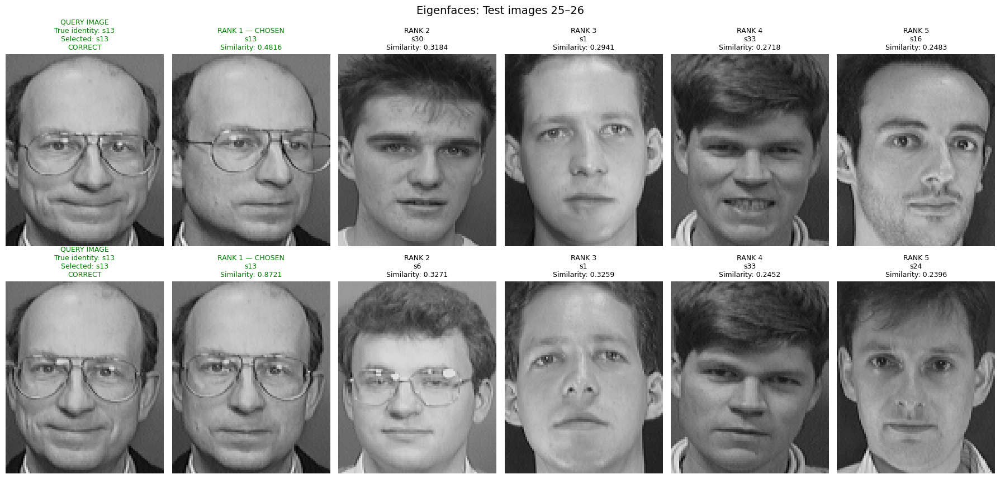

Test 27/76 | True: s14 | Selected: s14 | CORRECT | Top-1 similarity: 0.7705 | Top-5: s14, s11, s22, s21, s4
,Test 28/76 | True: s14 | Selected: s14 | CORRECT | Top-1 similarity: 0.6058 | Top-5: s14, s28, s37, s21, s9


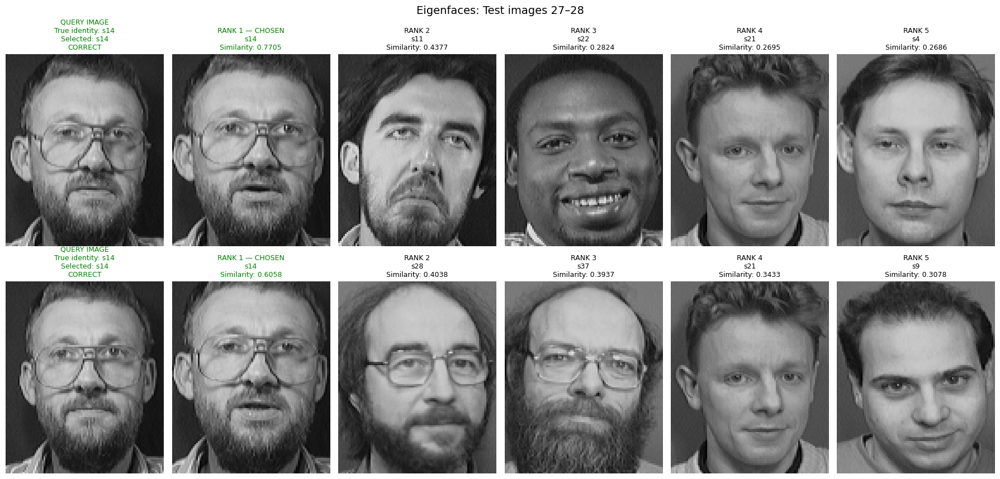

Test 29/76 | True: s15 | Selected: s15 | CORRECT | Top-1 similarity: 0.8406 | Top-5: s15, s8, s18, s35, s28
,Test 30/76 | True: s15 | Selected: s15 | CORRECT | Top-1 similarity: 0.8249 | Top-5: s15, s8, s26, s35, s18


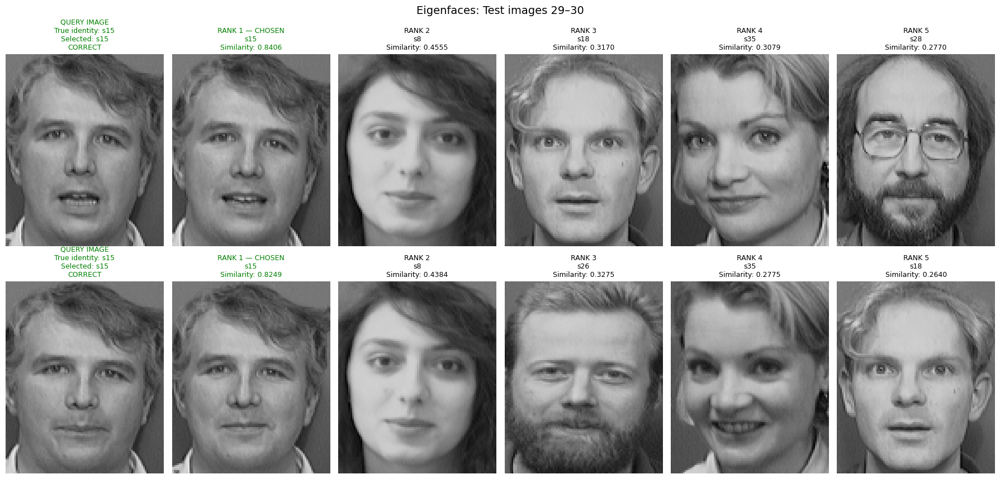

Test 31/76 | True: s16 | Selected: s16 | CORRECT | Top-1 similarity: 0.4599 | Top-5: s16, s1, s11, s6, s24
,Test 32/76 | True: s16 | Selected: s16 | CORRECT | Top-1 similarity: 0.8359 | Top-5: s16, s27, s1, s9, s25


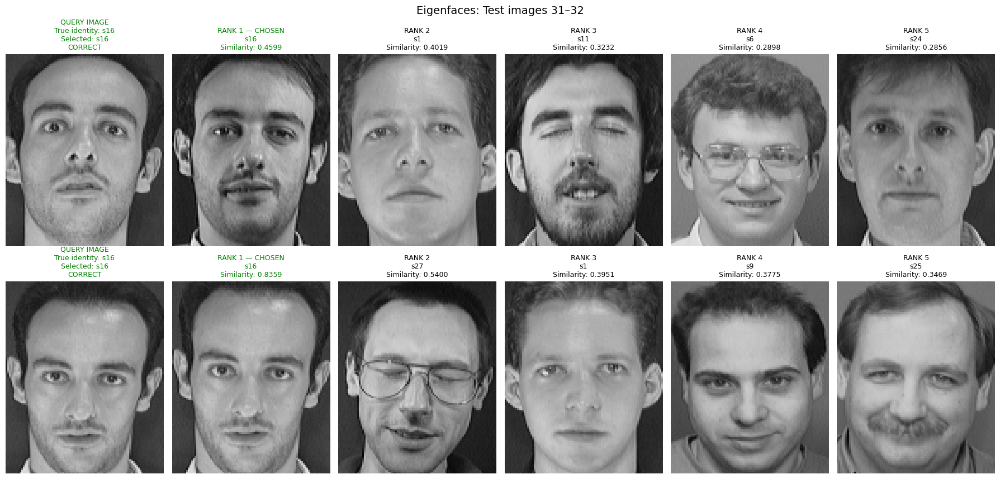

Test 33/76 | True: s17 | Selected: s17 | CORRECT | Top-1 similarity: 0.8686 | Top-5: s17, s9, s30, s4, s5
,Test 34/76 | True: s17 | Selected: s17 | CORRECT | Top-1 similarity: 0.8959 | Top-5: s17, s5, s9, s25, s4


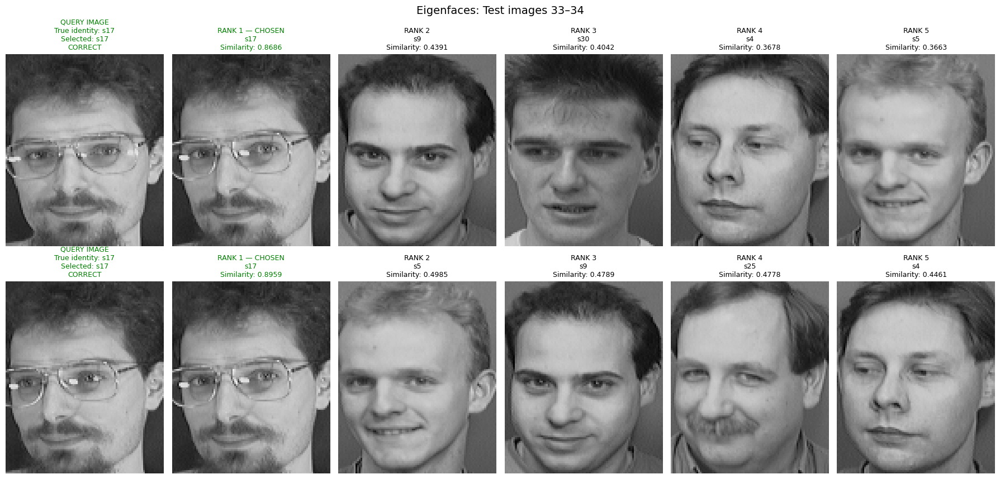

Test 35/76 | True: s18 | Selected: s18 | CORRECT | Top-1 similarity: 0.7619 | Top-5: s18, s4, s20, s33, s30
,Test 36/76 | True: s18 | Selected: s18 | CORRECT | Top-1 similarity: 0.7002 | Top-5: s18, s12, s1, s9, s24


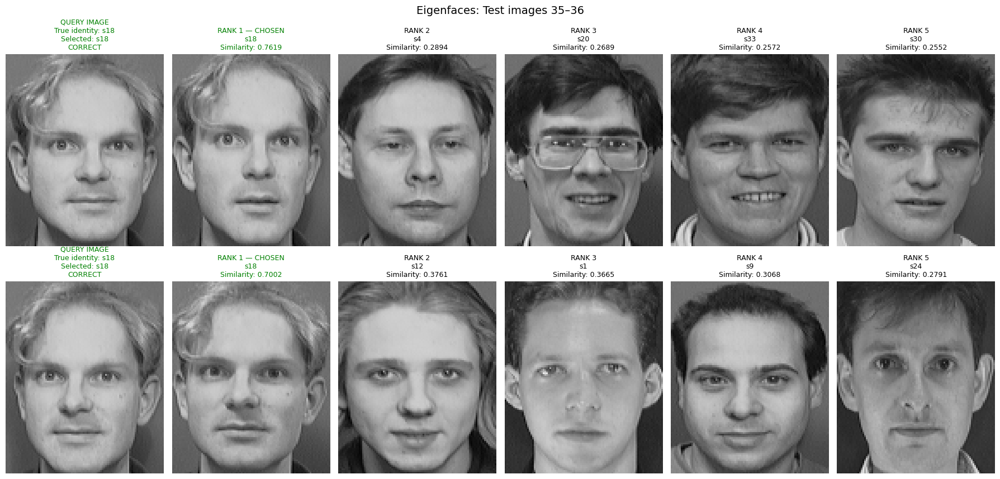

Test 37/76 | True: s19 | Selected: s8 | WRONG | Top-1 similarity: 0.5640 | Top-5: s8, s24, s11, s32, s19
,Test 38/76 | True: s19 | Selected: s19 | CORRECT | Top-1 similarity: 0.8386 | Top-5: s19, s36, s27, s16, s11


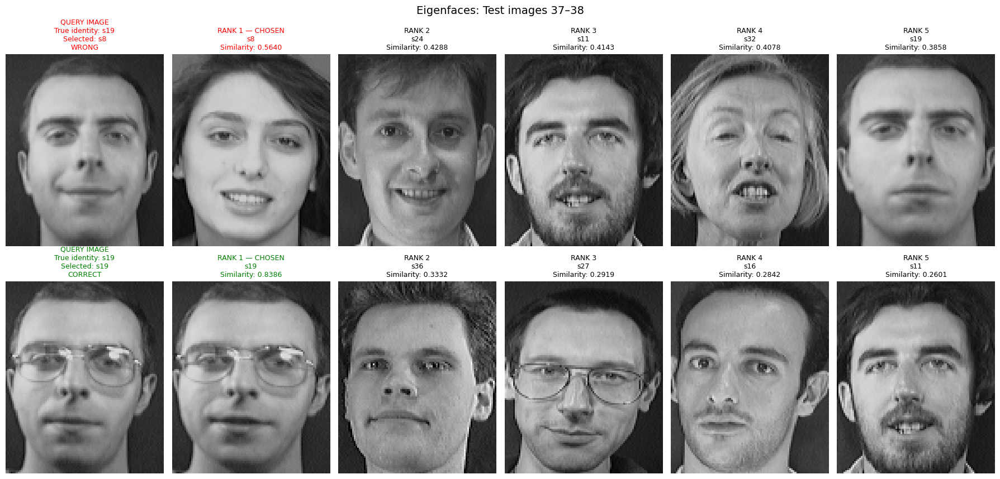

Test 39/76 | True: s20 | Selected: s20 | CORRECT | Top-1 similarity: 0.8426 | Top-5: s20, s4, s35, s38, s26
,Test 40/76 | True: s20 | Selected: s20 | CORRECT | Top-1 similarity: 0.8616 | Top-5: s20, s18, s4, s3, s25


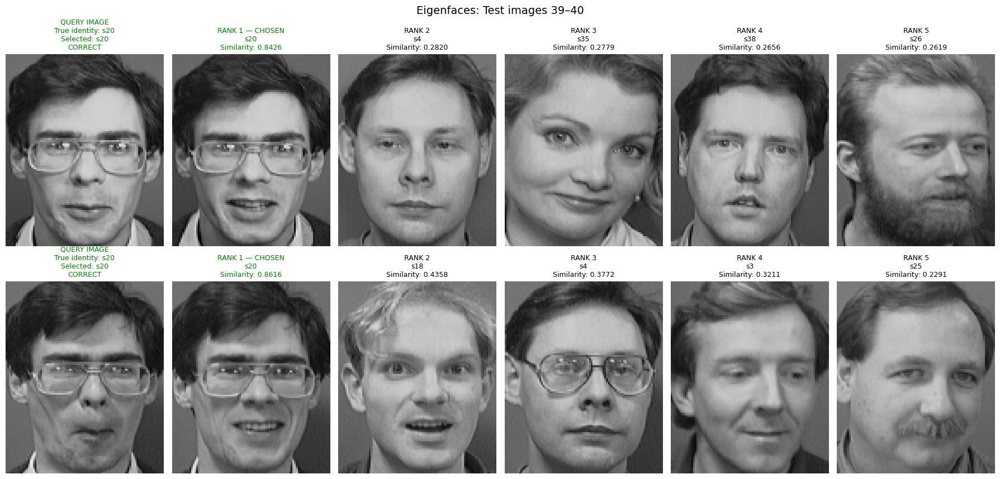

Test 41/76 | True: s21 | Selected: s21 | CORRECT | Top-1 similarity: 0.8036 | Top-5: s21, s31, s14, s30, s34
,Test 42/76 | True: s21 | Selected: s21 | CORRECT | Top-1 similarity: 0.8406 | Top-5: s21, s31, s33, s14, s34


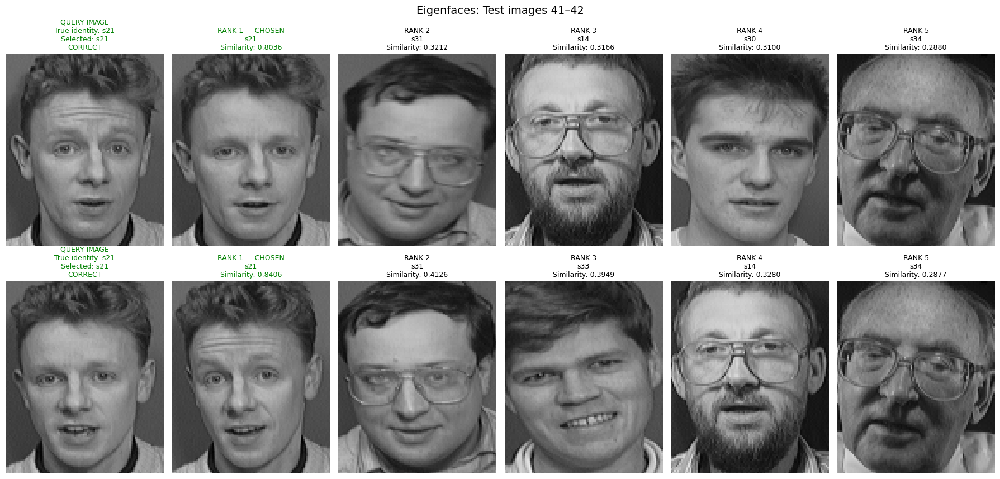

Test 43/76 | True: s22 | Selected: s22 | CORRECT | Top-1 similarity: 0.7642 | Top-5: s22, s28, s20, s11, s8
,Test 44/76 | True: s22 | Selected: s22 | CORRECT | Top-1 similarity: 0.7196 | Top-5: s22, s14, s37, s28, s13


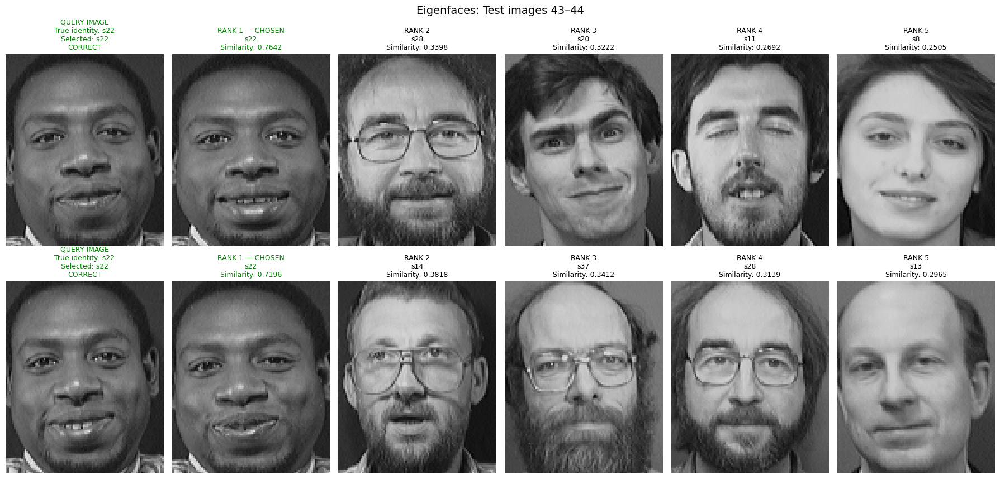

Test 45/76 | True: s23 | Selected: s23 | CORRECT | Top-1 similarity: 0.7856 | Top-5: s23, s38, s29, s9, s5
,Test 46/76 | True: s23 | Selected: s23 | CORRECT | Top-1 similarity: 0.7269 | Top-5: s23, s17, s38, s26, s21


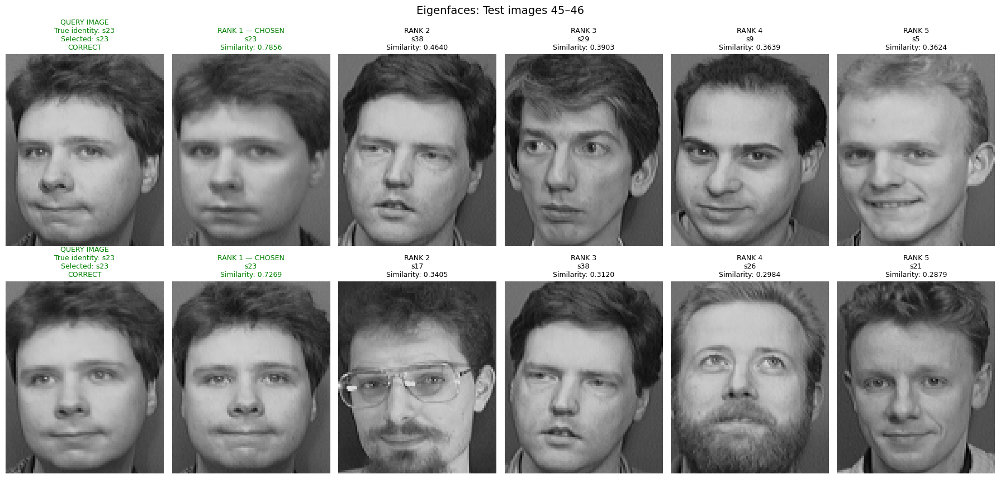

Test 47/76 | True: s24 | Selected: s24 | CORRECT | Top-1 similarity: 0.5896 | Top-5: s24, s1, s30, s17, s35
,Test 48/76 | True: s24 | Selected: s24 | CORRECT | Top-1 similarity: 0.6135 | Top-5: s24, s1, s21, s30, s35


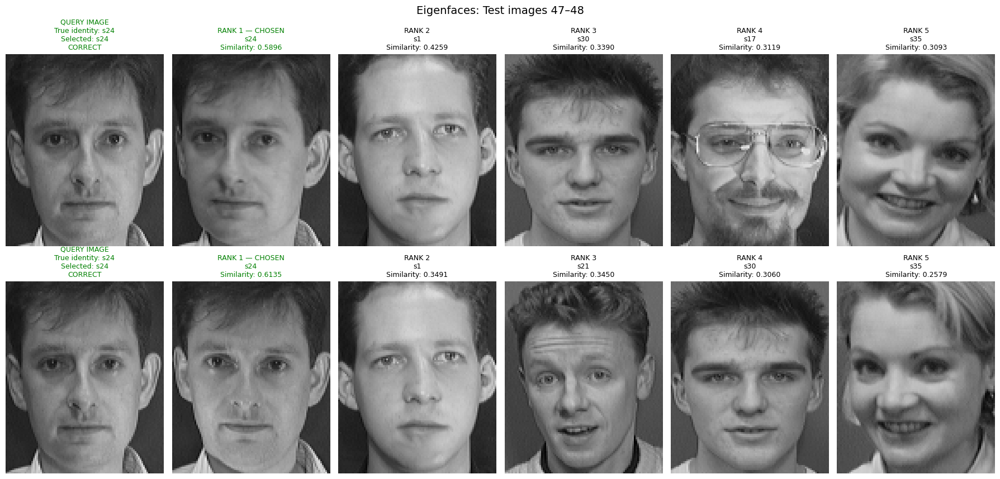

Test 49/76 | True: s25 | Selected: s25 | CORRECT | Top-1 similarity: 0.8183 | Top-5: s25, s4, s27, s17, s16
,Test 50/76 | True: s25 | Selected: s25 | CORRECT | Top-1 similarity: 0.8140 | Top-5: s25, s4, s9, s30, s17


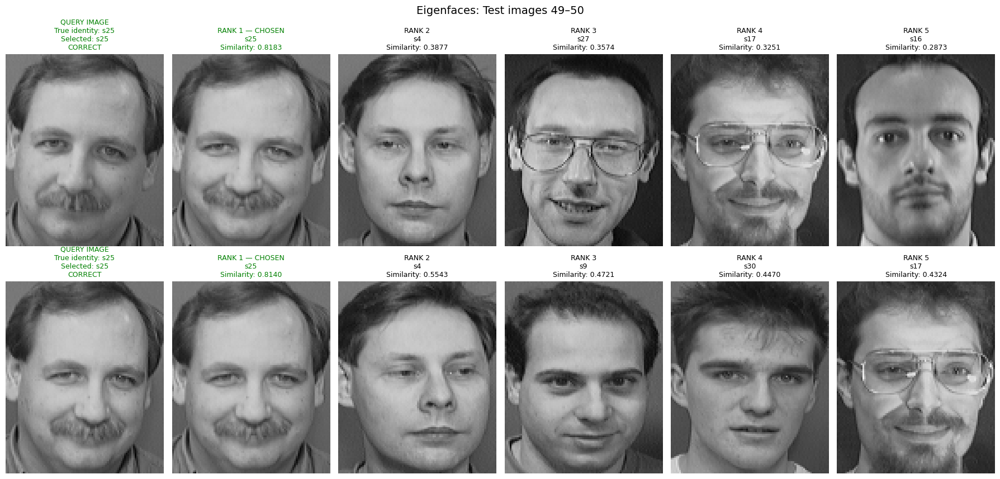

Test 51/76 | True: s26 | Selected: s26 | CORRECT | Top-1 similarity: 0.7233 | Top-5: s26, s21, s25, s28, s9
,Test 52/76 | True: s26 | Selected: s26 | CORRECT | Top-1 similarity: 0.9335 | Top-5: s26, s9, s23, s21, s28


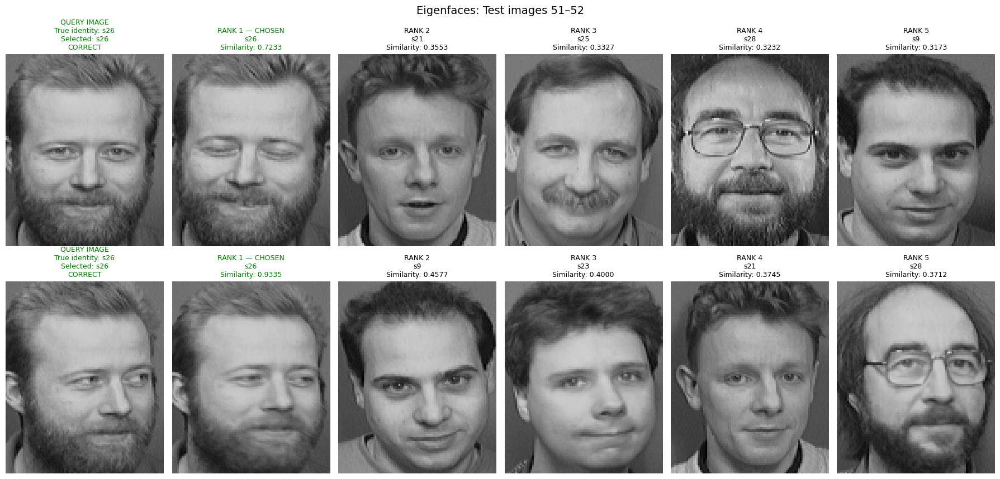

Test 53/76 | True: s27 | Selected: s27 | CORRECT | Top-1 similarity: 0.9423 | Top-5: s27, s16, s4, s25, s12
,Test 54/76 | True: s27 | Selected: s27 | CORRECT | Top-1 similarity: 0.7882 | Top-5: s27, s16, s1, s8, s38


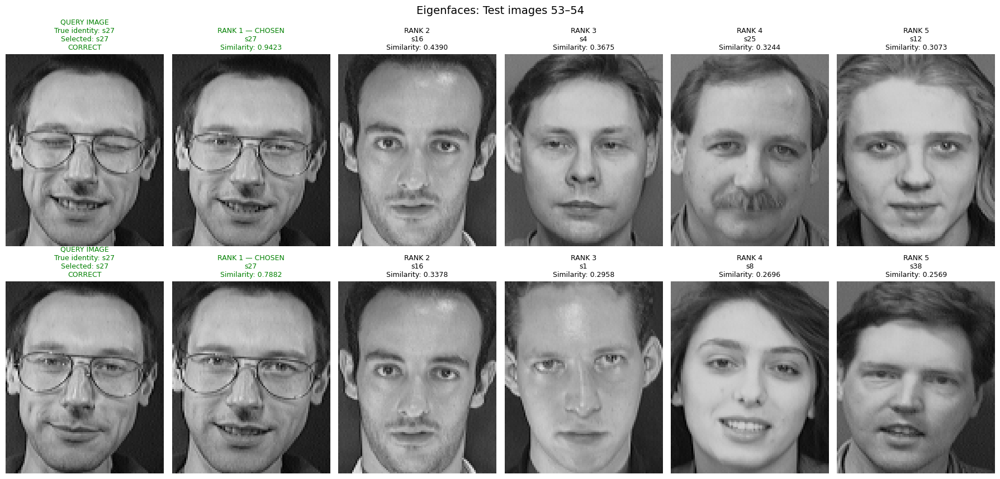

Test 55/76 | True: s28 | Selected: s28 | CORRECT | Top-1 similarity: 0.4646 | Top-5: s28, s17, s31, s4, s30
,Test 56/76 | True: s28 | Selected: s28 | CORRECT | Top-1 similarity: 0.6674 | Top-5: s28, s14, s6, s33, s37


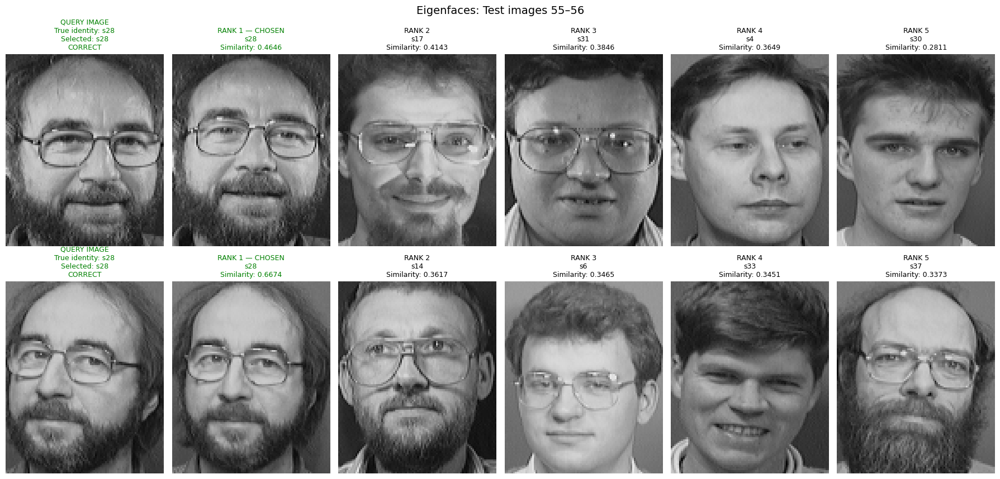

Test 57/76 | True: s29 | Selected: s29 | CORRECT | Top-1 similarity: 0.5737 | Top-5: s29, s23, s25, s6, s5
,Test 58/76 | True: s29 | Selected: s29 | CORRECT | Top-1 similarity: 0.6706 | Top-5: s29, s13, s7, s20, s11


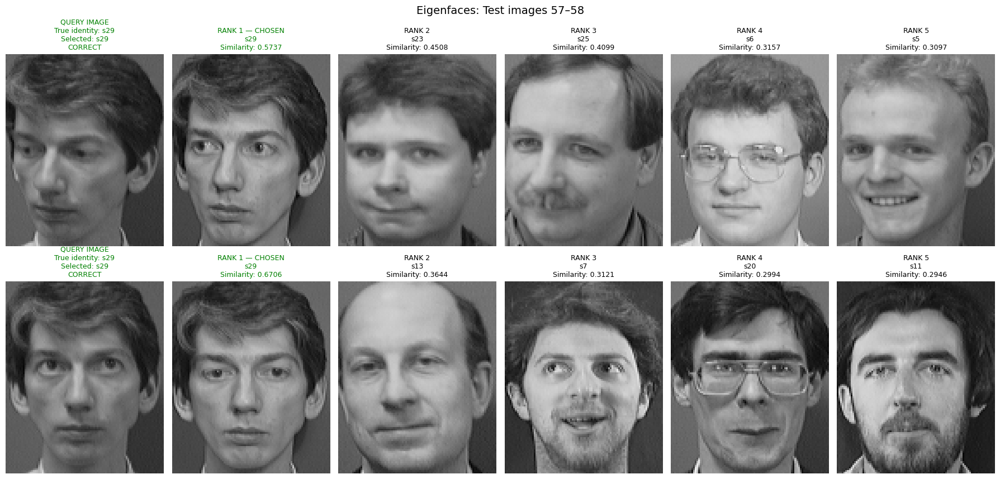

Test 59/76 | True: s30 | Selected: s30 | CORRECT | Top-1 similarity: 0.6650 | Top-5: s30, s9, s12, s31, s5
,Test 60/76 | True: s30 | Selected: s30 | CORRECT | Top-1 similarity: 0.7717 | Top-5: s30, s35, s12, s17, s25


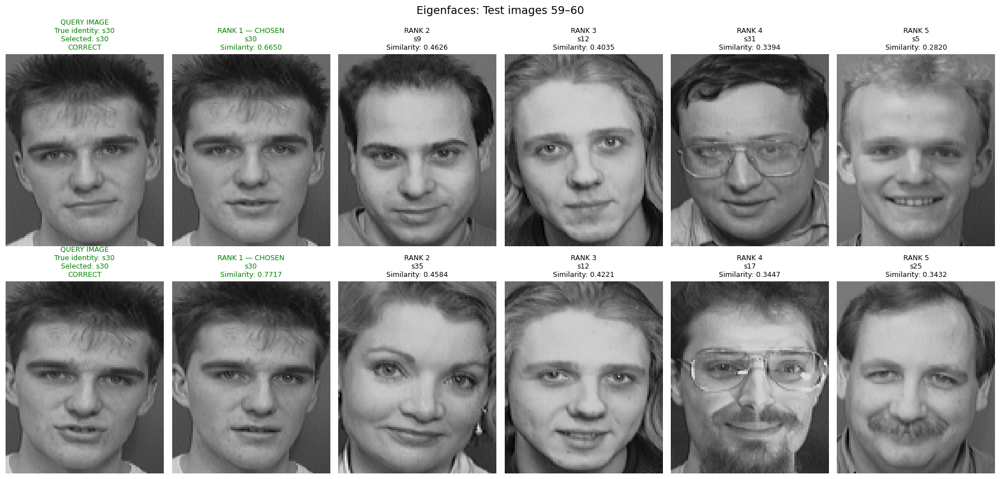

Test 61/76 | True: s31 | Selected: s31 | CORRECT | Top-1 similarity: 0.7138 | Top-5: s31, s9, s21, s25, s34
,Test 62/76 | True: s31 | Selected: s31 | CORRECT | Top-1 similarity: 0.8204 | Top-5: s31, s36, s26, s18, s17


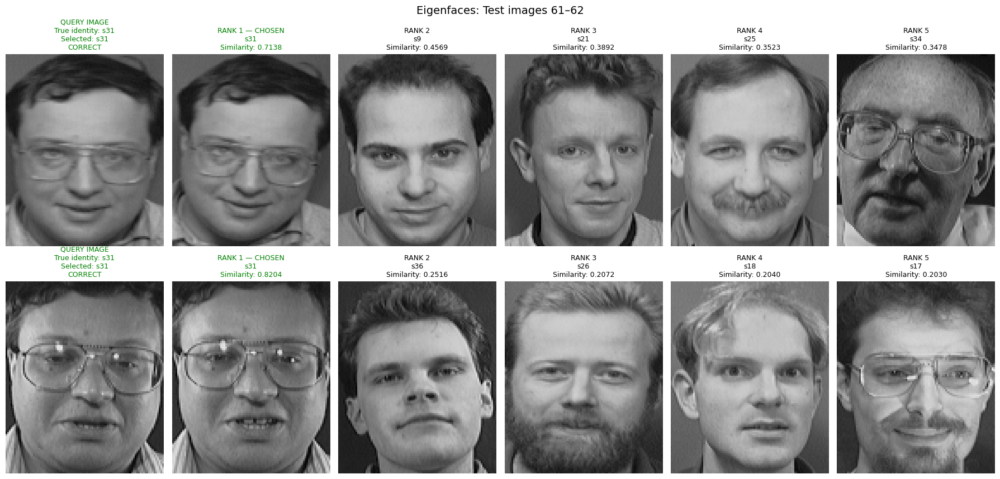

Test 63/76 | True: s32 | Selected: s32 | CORRECT | Top-1 similarity: 0.7058 | Top-5: s32, s8, s26, s17, s2
,Test 64/76 | True: s32 | Selected: s32 | CORRECT | Top-1 similarity: 0.8555 | Top-5: s32, s8, s27, s11, s7


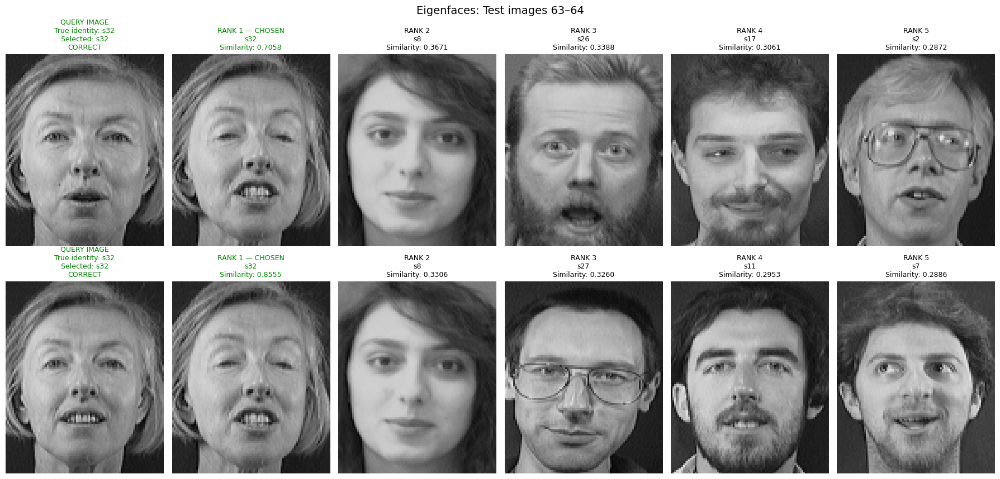

Test 65/76 | True: s33 | Selected: s33 | CORRECT | Top-1 similarity: 0.7098 | Top-5: s33, s20, s28, s34, s14
,Test 66/76 | True: s33 | Selected: s33 | CORRECT | Top-1 similarity: 0.9788 | Top-5: s33, s1, s23, s13, s6


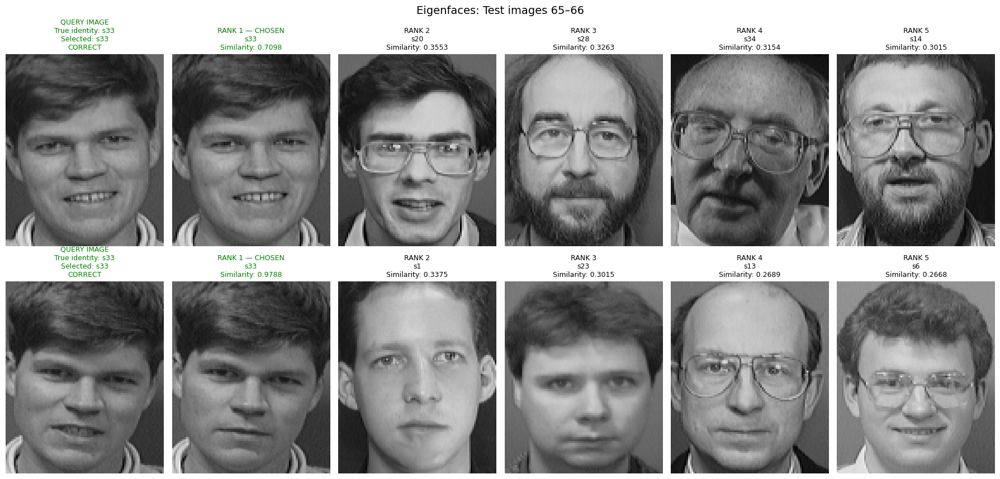

Test 67/76 | True: s34 | Selected: s34 | CORRECT | Top-1 similarity: 0.7276 | Top-5: s34, s31, s9, s25, s21
,Test 68/76 | True: s34 | Selected: s34 | CORRECT | Top-1 similarity: 0.8945 | Top-5: s34, s31, s9, s25, s4


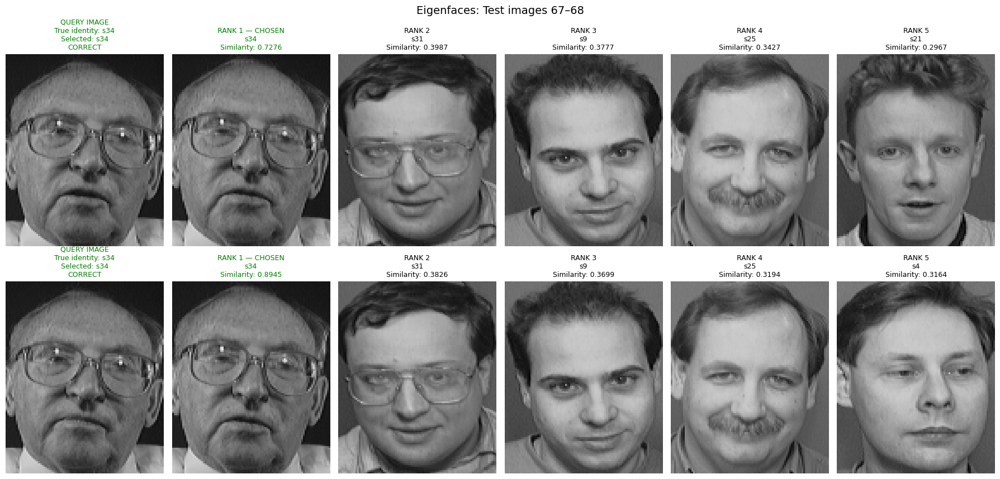

Test 69/76 | True: s35 | Selected: s35 | CORRECT | Top-1 similarity: 0.7339 | Top-5: s35, s1, s37, s21, s13
,Test 70/76 | True: s35 | Selected: s35 | CORRECT | Top-1 similarity: 0.7194 | Top-5: s35, s21, s24, s33, s1


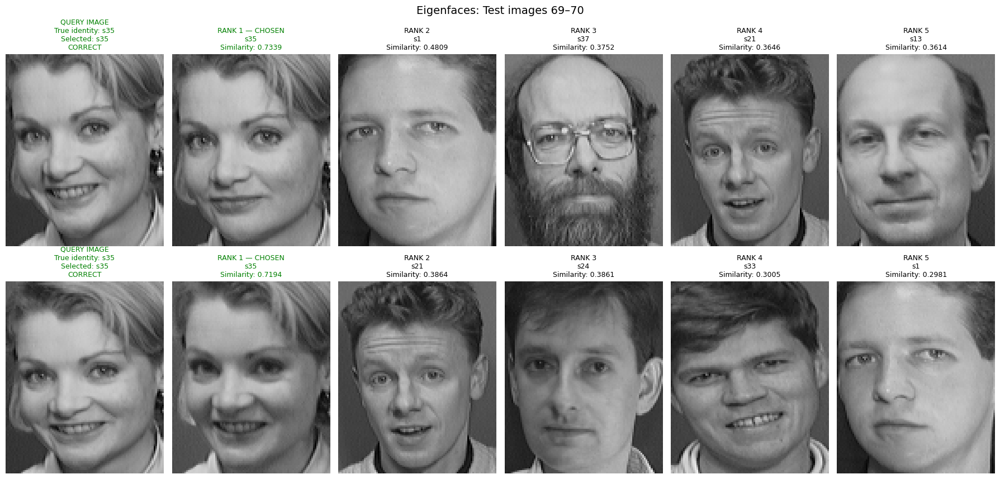

Test 71/76 | True: s36 | Selected: s36 | CORRECT | Top-1 similarity: 0.6334 | Top-5: s36, s17, s12, s9, s4
,Test 72/76 | True: s36 | Selected: s36 | CORRECT | Top-1 similarity: 0.5526 | Top-5: s36, s4, s11, s9, s22


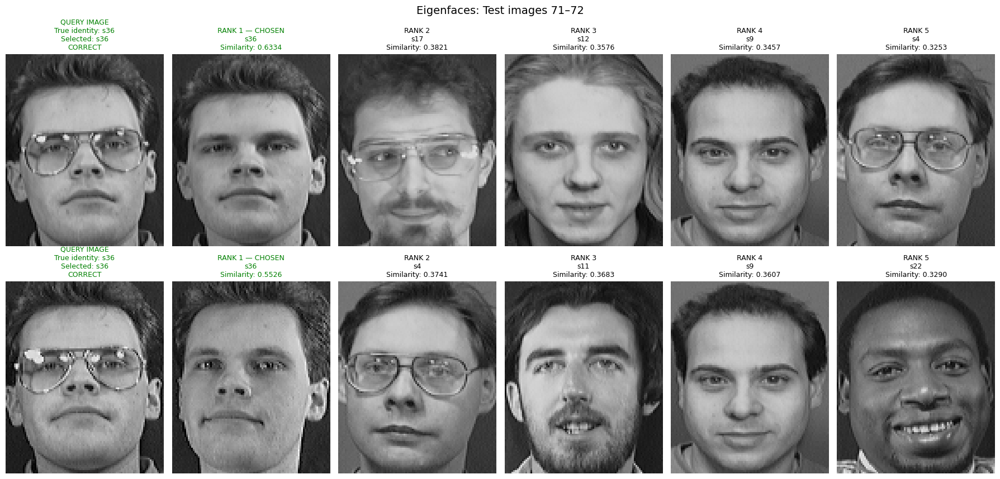

Test 73/76 | True: s37 | Selected: s37 | CORRECT | Top-1 similarity: 0.9280 | Top-5: s37, s28, s6, s22, s20
,Test 74/76 | True: s37 | Selected: s37 | CORRECT | Top-1 similarity: 0.7799 | Top-5: s37, s28, s6, s26, s10


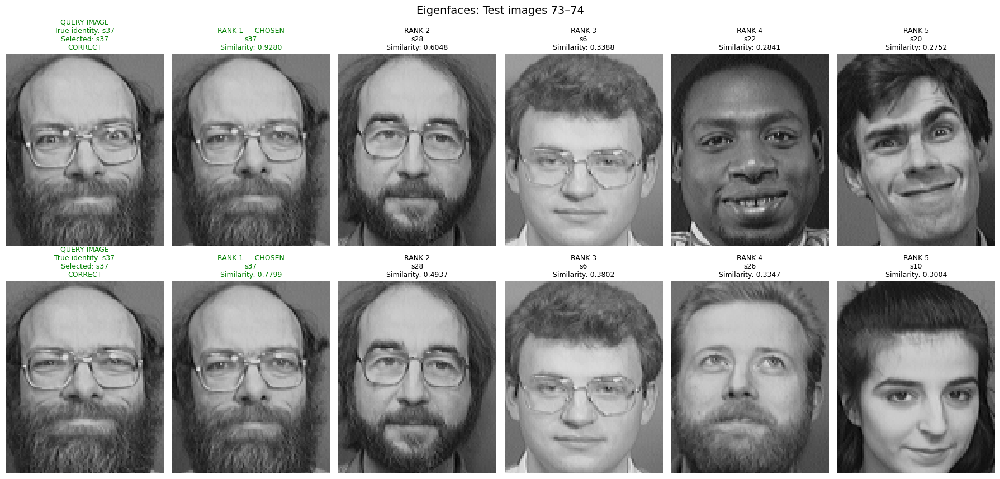

Test 75/76 | True: s38 | Selected: s38 | CORRECT | Top-1 similarity: 0.6318 | Top-5: s38, s3, s4, s36, s13
,Test 76/76 | True: s38 | Selected: s38 | CORRECT | Top-1 similarity: 0.8169 | Top-5: s38, s14, s23, s13, s30


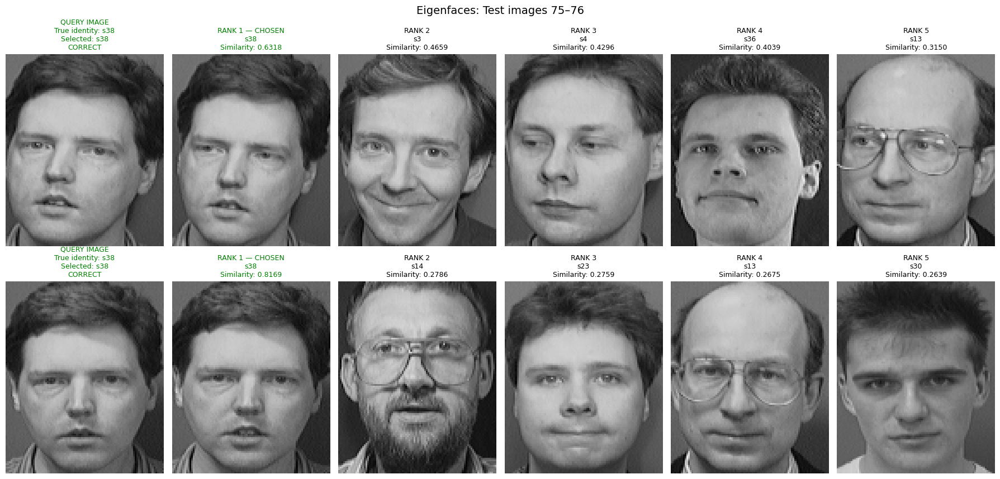


,===========================================================================
,Fisherfaces: TOP-5 RESULTS FOR ALL 76 TEST IMAGES
,===========================================================================
,Test 01/76 | True: s1 | Selected: s1 | CORRECT | Top-1 similarity: 0.8143 | Top-5: s1, s13, s24, s16, s36
,Test 02/76 | True: s1 | Selected: s17 | WRONG | Top-1 similarity: 0.4611 | Top-5: s17, s16, s27, s1, s18


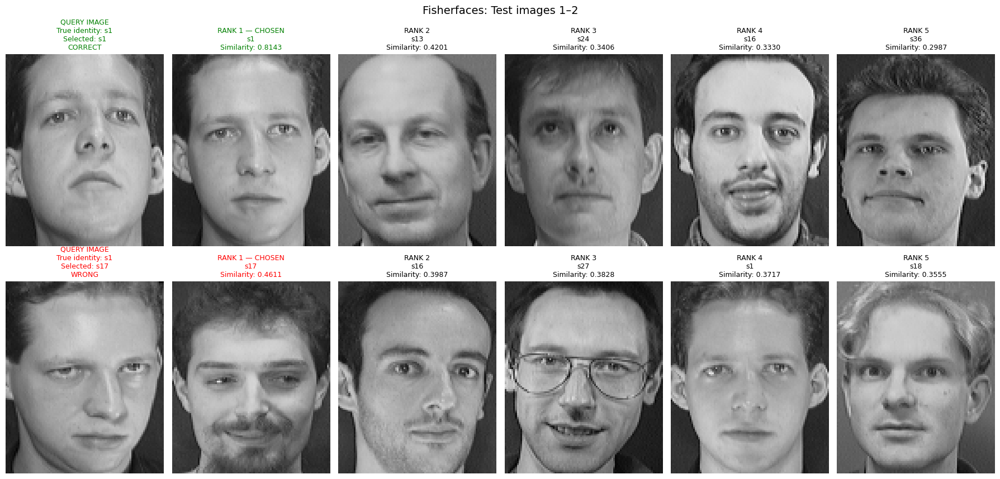

Test 03/76 | True: s2 | Selected: s2 | CORRECT | Top-1 similarity: 0.8242 | Top-5: s2, s14, s1, s16, s19
,Test 04/76 | True: s2 | Selected: s2 | CORRECT | Top-1 similarity: 0.9484 | Top-5: s2, s14, s1, s32, s27


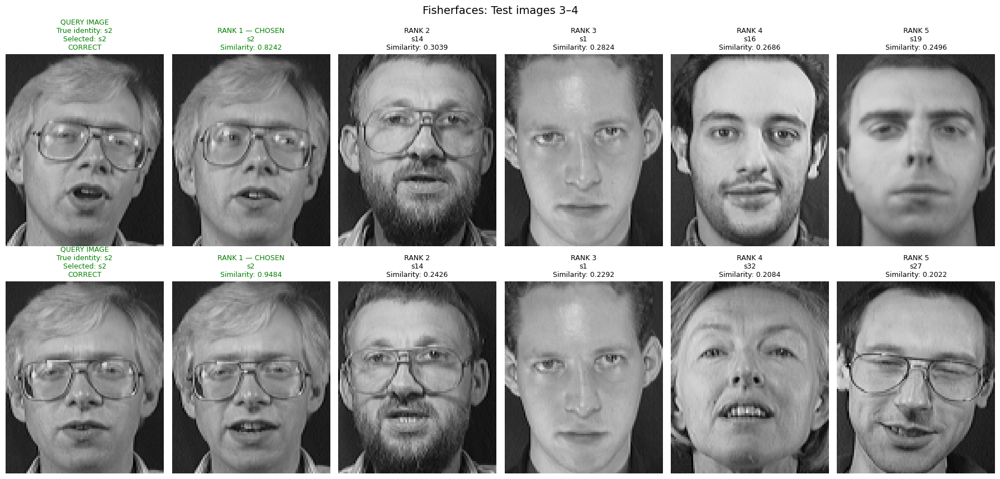

Test 05/76 | True: s3 | Selected: s3 | CORRECT | Top-1 similarity: 0.9071 | Top-5: s3, s26, s25, s5, s12
,Test 06/76 | True: s3 | Selected: s3 | CORRECT | Top-1 similarity: 0.8252 | Top-5: s3, s5, s26, s25, s37


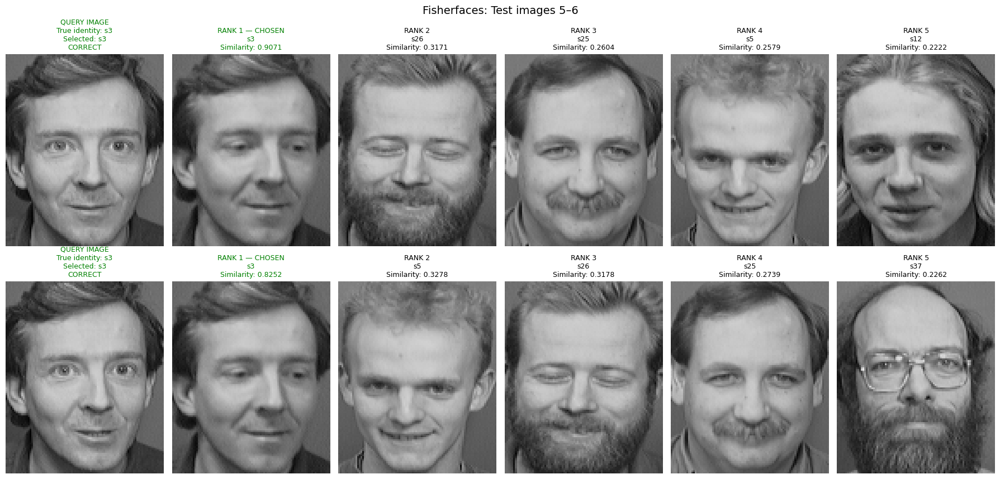

Test 07/76 | True: s4 | Selected: s4 | CORRECT | Top-1 similarity: 0.9258 | Top-5: s4, s25, s9, s26, s38
,Test 08/76 | True: s4 | Selected: s4 | CORRECT | Top-1 similarity: 0.6869 | Top-5: s4, s25, s23, s3, s26


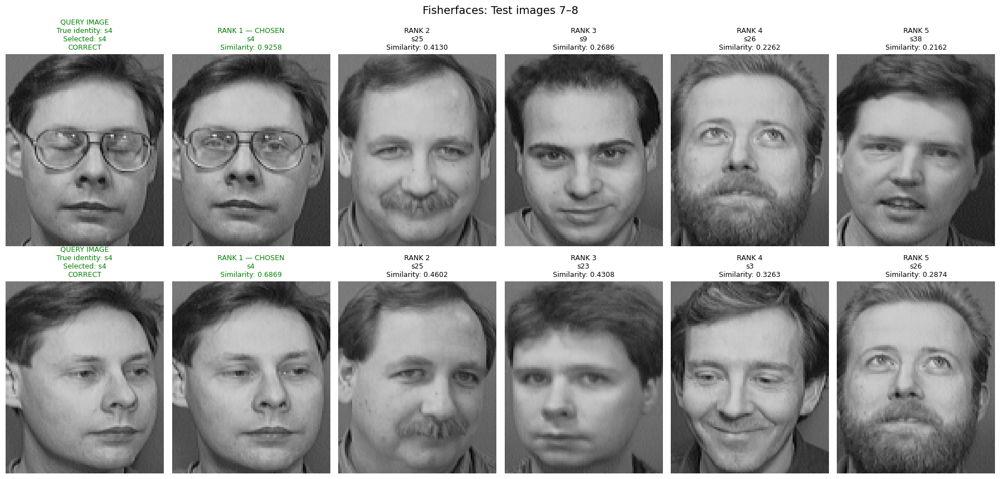

Test 09/76 | True: s5 | Selected: s5 | CORRECT | Top-1 similarity: 0.8835 | Top-5: s5, s12, s3, s18, s26
,Test 10/76 | True: s5 | Selected: s5 | CORRECT | Top-1 similarity: 0.5118 | Top-5: s5, s36, s12, s18, s13


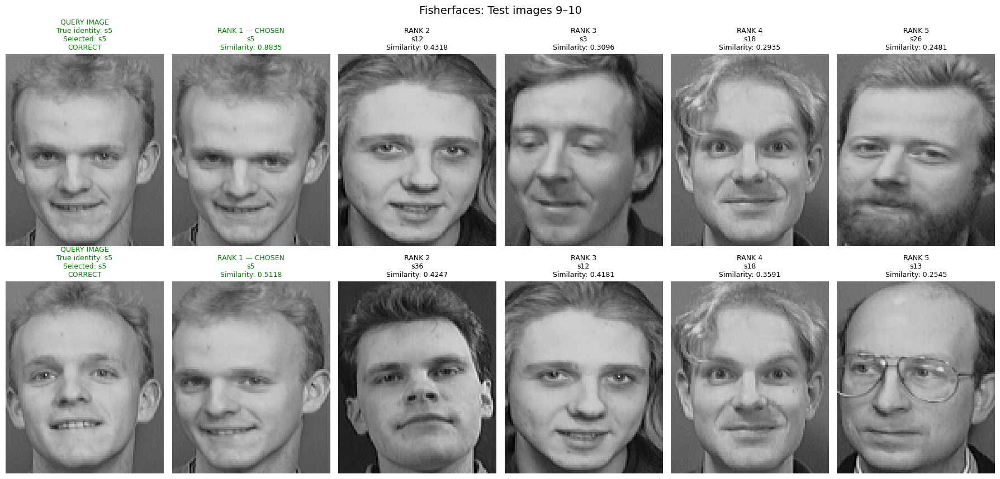

Test 11/76 | True: s6 | Selected: s6 | CORRECT | Top-1 similarity: 0.8033 | Top-5: s6, s33, s29, s20, s10
,Test 12/76 | True: s6 | Selected: s6 | CORRECT | Top-1 similarity: 0.9860 | Top-5: s6, s33, s30, s38, s20


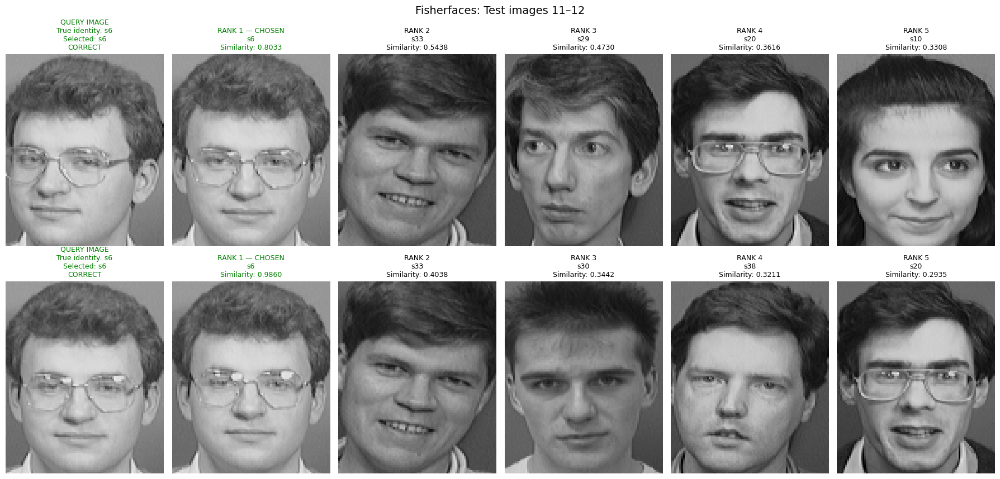

Test 13/76 | True: s7 | Selected: s7 | CORRECT | Top-1 similarity: 0.9753 | Top-5: s7, s36, s29, s20, s33
,Test 14/76 | True: s7 | Selected: s7 | CORRECT | Top-1 similarity: 0.8791 | Top-5: s7, s36, s20, s29, s24


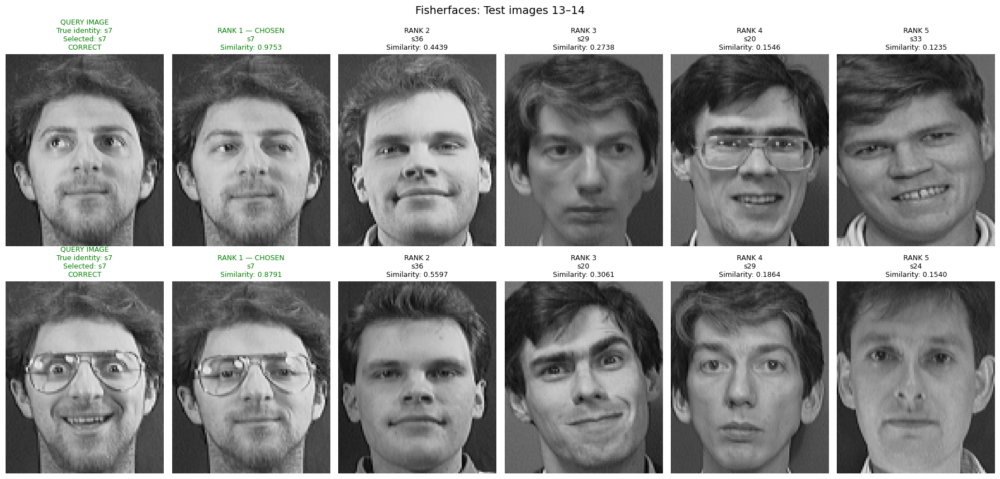

Test 15/76 | True: s8 | Selected: s8 | CORRECT | Top-1 similarity: 0.8993 | Top-5: s8, s19, s10, s17, s15
,Test 16/76 | True: s8 | Selected: s8 | CORRECT | Top-1 similarity: 0.9410 | Top-5: s8, s35, s15, s19, s17


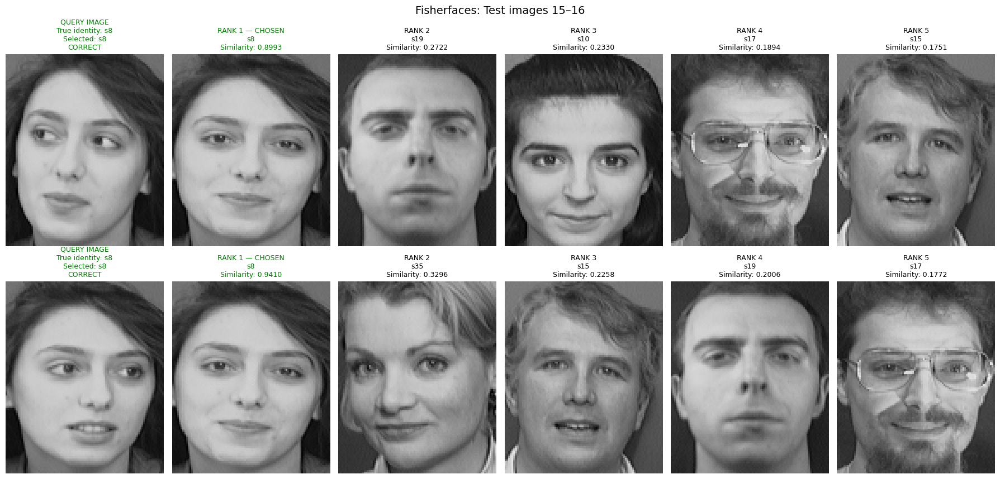

Test 17/76 | True: s9 | Selected: s9 | CORRECT | Top-1 similarity: 0.9311 | Top-5: s9, s31, s30, s23, s38
,Test 18/76 | True: s9 | Selected: s9 | CORRECT | Top-1 similarity: 0.8421 | Top-5: s9, s25, s26, s23, s3


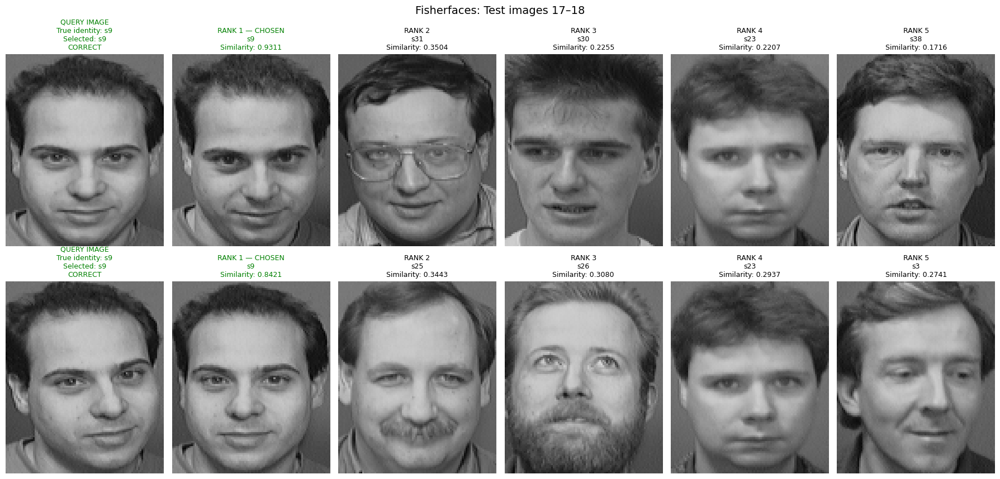

Test 19/76 | True: s10 | Selected: s10 | CORRECT | Top-1 similarity: 0.7161 | Top-5: s10, s5, s6, s29, s30
,Test 20/76 | True: s10 | Selected: s10 | CORRECT | Top-1 similarity: 0.6239 | Top-5: s10, s8, s5, s18, s3


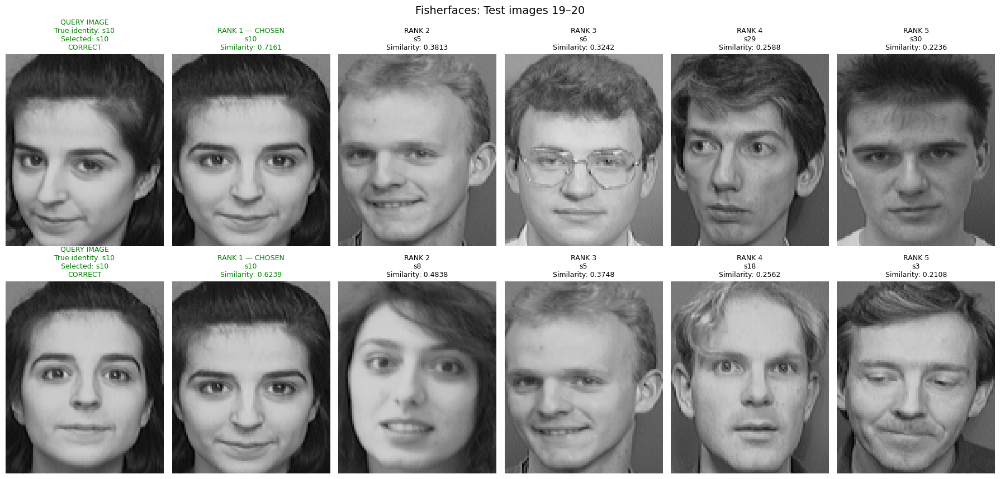

Test 21/76 | True: s11 | Selected: s11 | CORRECT | Top-1 similarity: 0.8808 | Top-5: s11, s14, s22, s28, s19
,Test 22/76 | True: s11 | Selected: s11 | CORRECT | Top-1 similarity: 0.9033 | Top-5: s11, s15, s22, s38, s14


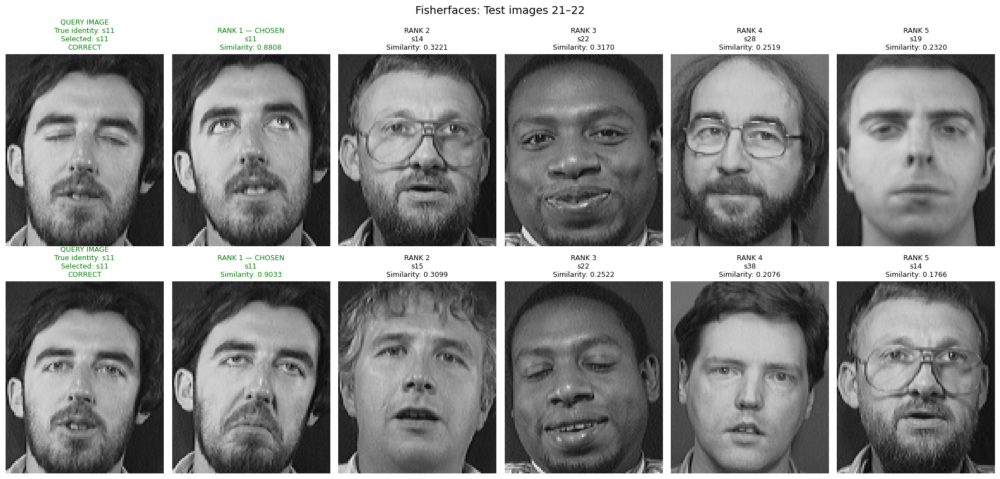

Test 23/76 | True: s12 | Selected: s12 | CORRECT | Top-1 similarity: 0.8871 | Top-5: s12, s5, s26, s18, s28
,Test 24/76 | True: s12 | Selected: s12 | CORRECT | Top-1 similarity: 0.9099 | Top-5: s12, s5, s26, s18, s32


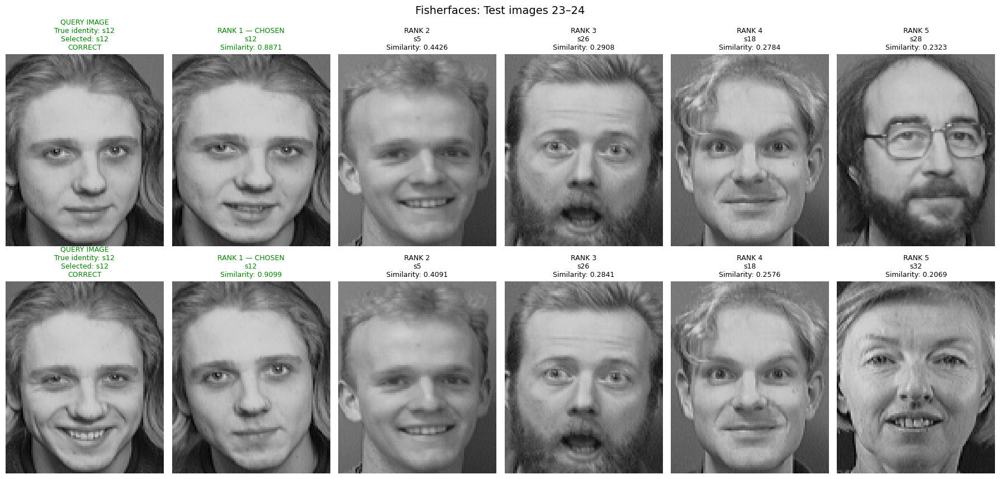

Test 25/76 | True: s13 | Selected: s13 | CORRECT | Top-1 similarity: 0.8020 | Top-5: s13, s1, s18, s5, s2
,Test 26/76 | True: s13 | Selected: s13 | CORRECT | Top-1 similarity: 0.9704 | Top-5: s13, s1, s18, s5, s2


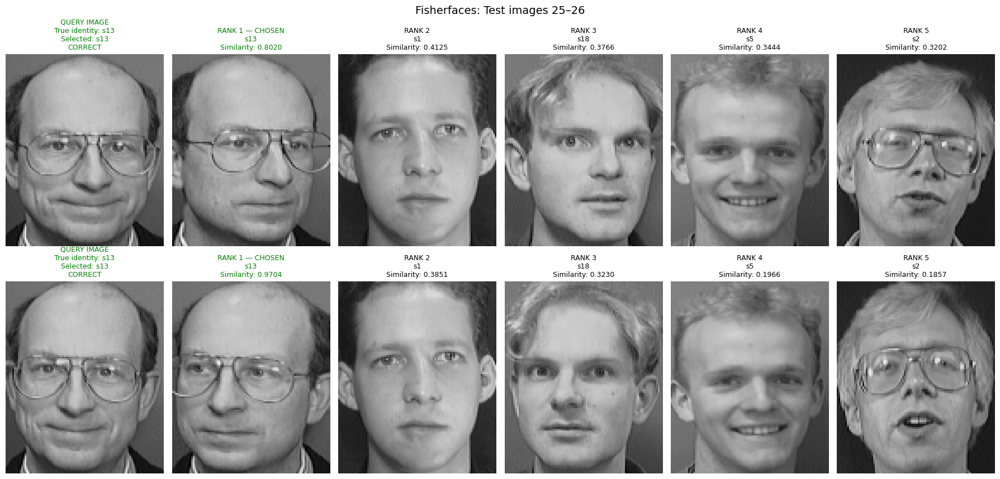

Test 27/76 | True: s14 | Selected: s14 | CORRECT | Top-1 similarity: 0.8446 | Top-5: s14, s11, s26, s22, s28
,Test 28/76 | True: s14 | Selected: s14 | CORRECT | Top-1 similarity: 0.7775 | Top-5: s14, s22, s37, s11, s28


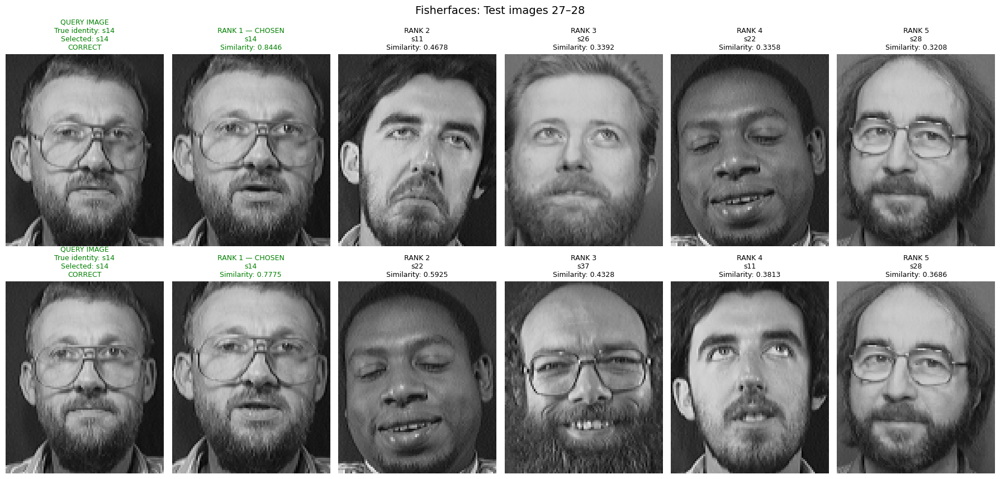

Test 29/76 | True: s15 | Selected: s15 | CORRECT | Top-1 similarity: 0.8968 | Top-5: s15, s8, s35, s33, s19
,Test 30/76 | True: s15 | Selected: s15 | CORRECT | Top-1 similarity: 0.9194 | Top-5: s15, s30, s6, s8, s33


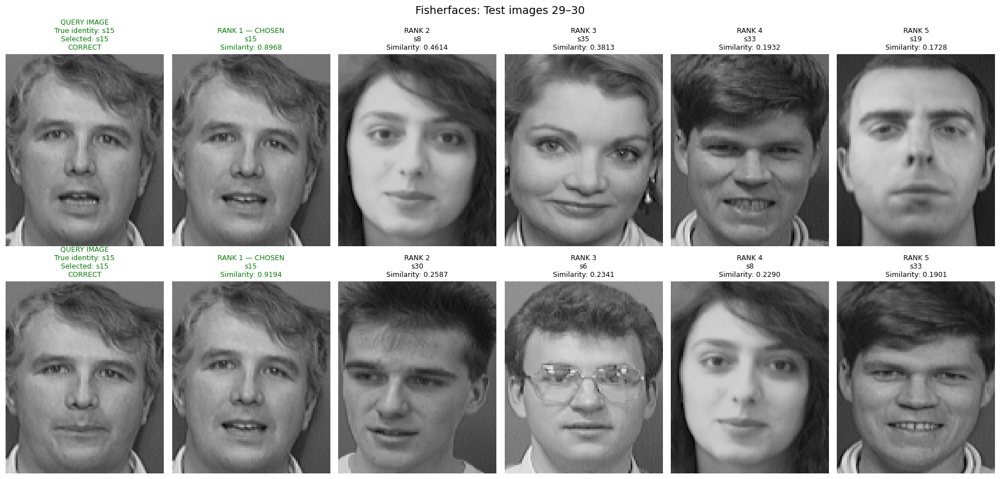

Test 31/76 | True: s16 | Selected: s16 | CORRECT | Top-1 similarity: 0.6633 | Top-5: s16, s1, s24, s6, s36
,Test 32/76 | True: s16 | Selected: s16 | CORRECT | Top-1 similarity: 0.8889 | Top-5: s16, s24, s1, s36, s18


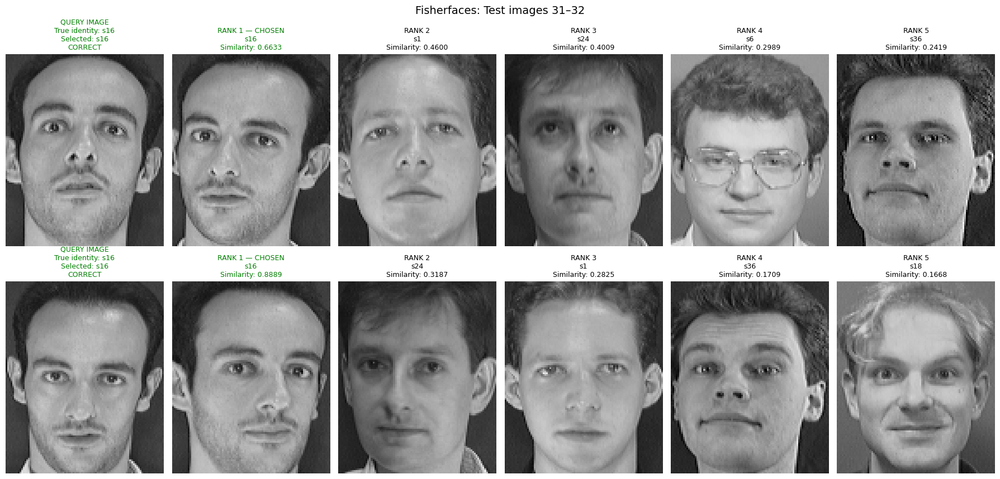

Test 33/76 | True: s17 | Selected: s17 | CORRECT | Top-1 similarity: 0.9167 | Top-5: s17, s36, s4, s23, s10
,Test 34/76 | True: s17 | Selected: s17 | CORRECT | Top-1 similarity: 0.8564 | Top-5: s17, s36, s24, s1, s19


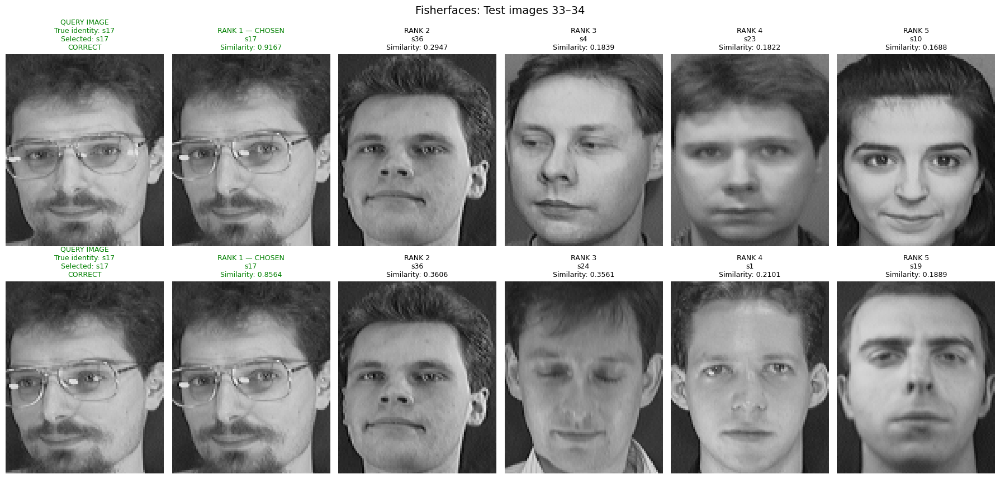

Test 35/76 | True: s18 | Selected: s18 | CORRECT | Top-1 similarity: 0.9388 | Top-5: s18, s5, s12, s26, s14
,Test 36/76 | True: s18 | Selected: s18 | CORRECT | Top-1 similarity: 0.8207 | Top-5: s18, s12, s13, s5, s3


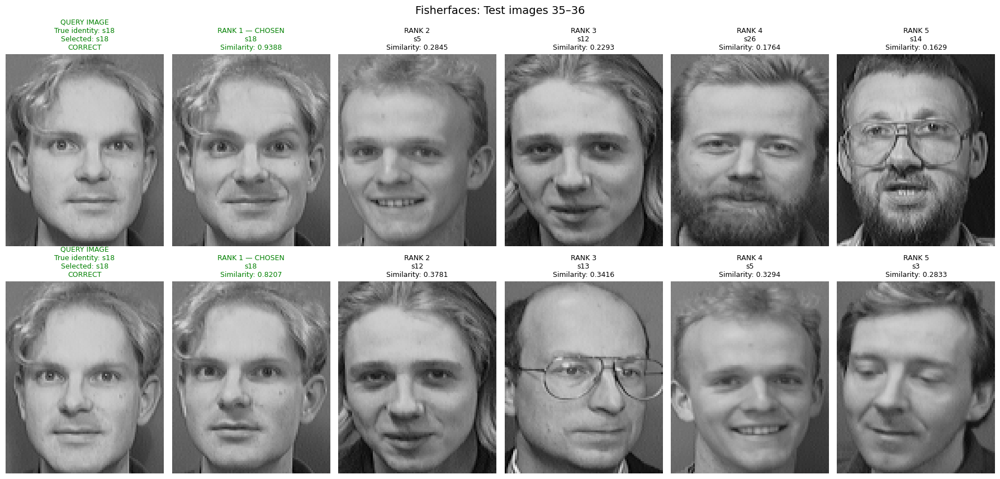

Test 37/76 | True: s19 | Selected: s8 | WRONG | Top-1 similarity: 0.5334 | Top-5: s8, s19, s11, s32, s1
,Test 38/76 | True: s19 | Selected: s19 | CORRECT | Top-1 similarity: 0.9395 | Top-5: s19, s32, s18, s14, s12


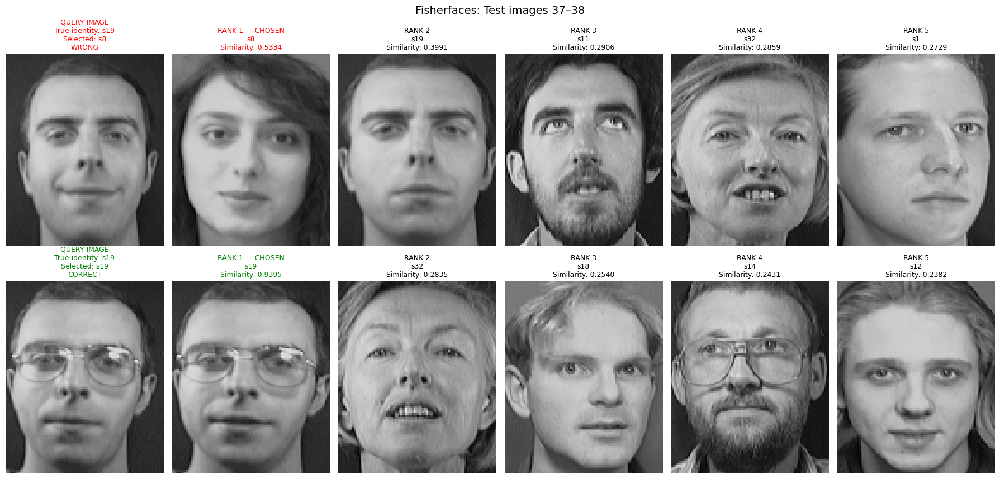

Test 39/76 | True: s20 | Selected: s20 | CORRECT | Top-1 similarity: 0.9523 | Top-5: s20, s33, s30, s29, s6
,Test 40/76 | True: s20 | Selected: s20 | CORRECT | Top-1 similarity: 0.9260 | Top-5: s20, s6, s33, s23, s29


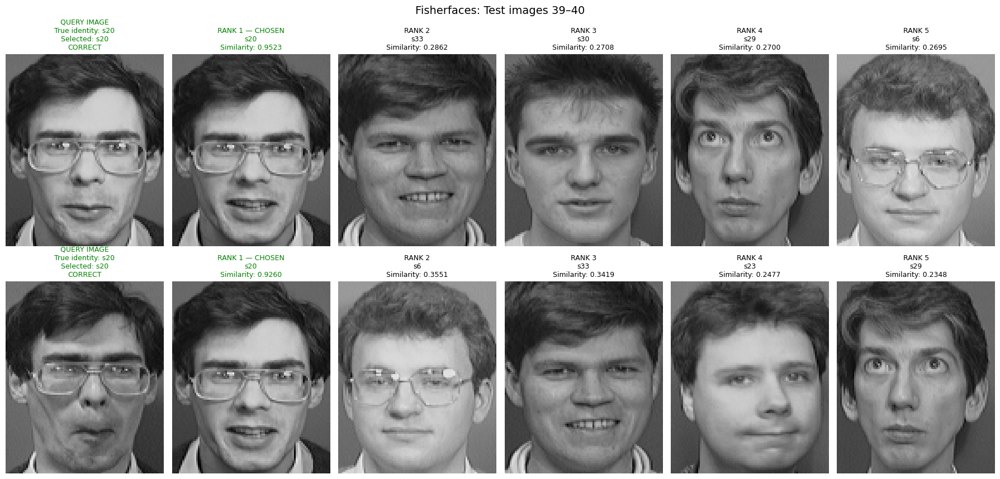

Test 41/76 | True: s21 | Selected: s21 | CORRECT | Top-1 similarity: 0.9367 | Top-5: s21, s30, s33, s38, s31
,Test 42/76 | True: s21 | Selected: s21 | CORRECT | Top-1 similarity: 0.9621 | Top-5: s21, s30, s31, s9, s22


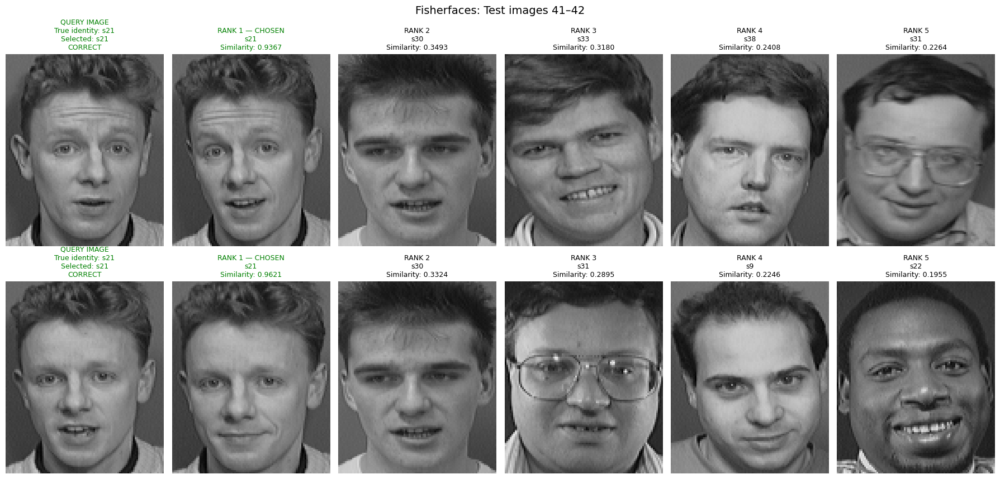

Test 43/76 | True: s22 | Selected: s22 | CORRECT | Top-1 similarity: 0.9303 | Top-5: s22, s14, s11, s28, s19
,Test 44/76 | True: s22 | Selected: s22 | CORRECT | Top-1 similarity: 0.7669 | Top-5: s22, s14, s34, s28, s11


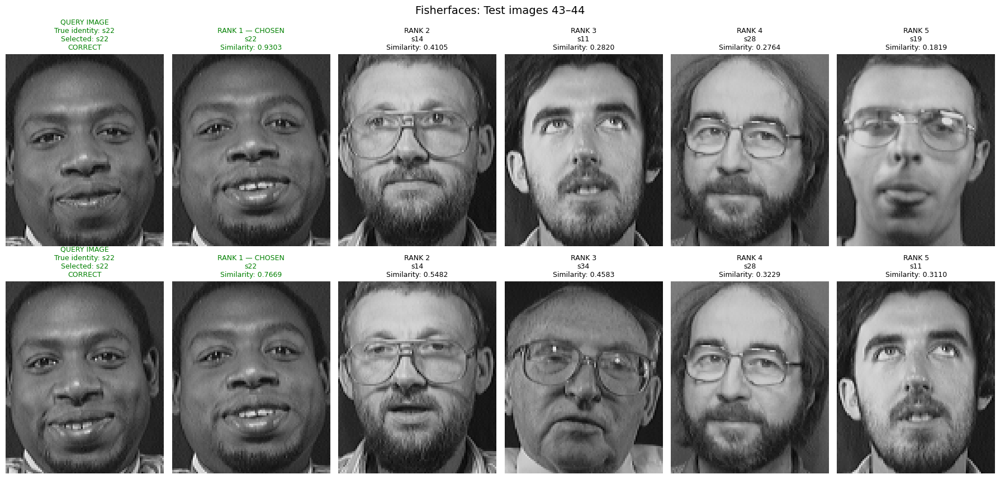

Test 45/76 | True: s23 | Selected: s23 | CORRECT | Top-1 similarity: 0.8568 | Top-5: s23, s38, s9, s21, s30
,Test 46/76 | True: s23 | Selected: s23 | CORRECT | Top-1 similarity: 0.8660 | Top-5: s23, s38, s4, s25, s30


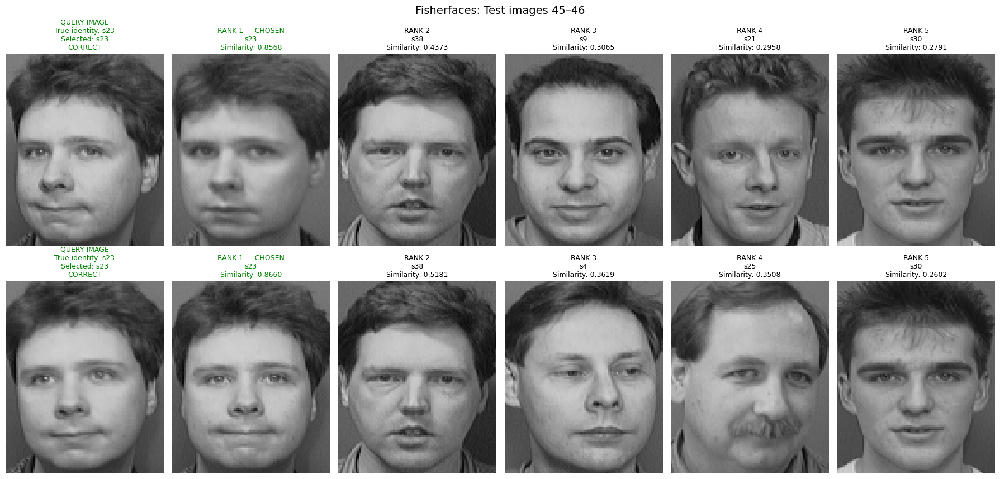

Test 47/76 | True: s24 | Selected: s24 | CORRECT | Top-1 similarity: 0.9404 | Top-5: s24, s1, s16, s36, s17
,Test 48/76 | True: s24 | Selected: s24 | CORRECT | Top-1 similarity: 0.9281 | Top-5: s24, s1, s16, s36, s33


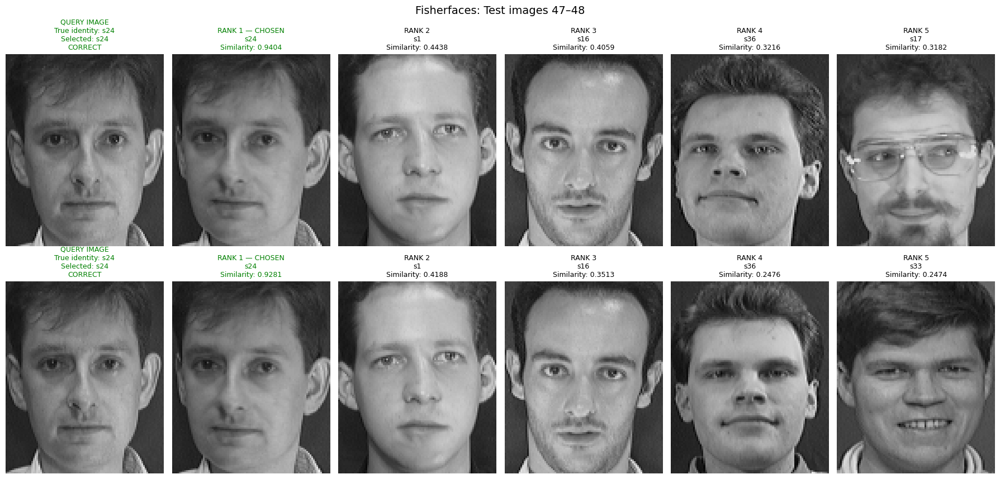

Test 49/76 | True: s25 | Selected: s25 | CORRECT | Top-1 similarity: 0.9341 | Top-5: s25, s4, s23, s9, s26
,Test 50/76 | True: s25 | Selected: s25 | CORRECT | Top-1 similarity: 0.9503 | Top-5: s25, s4, s9, s23, s26


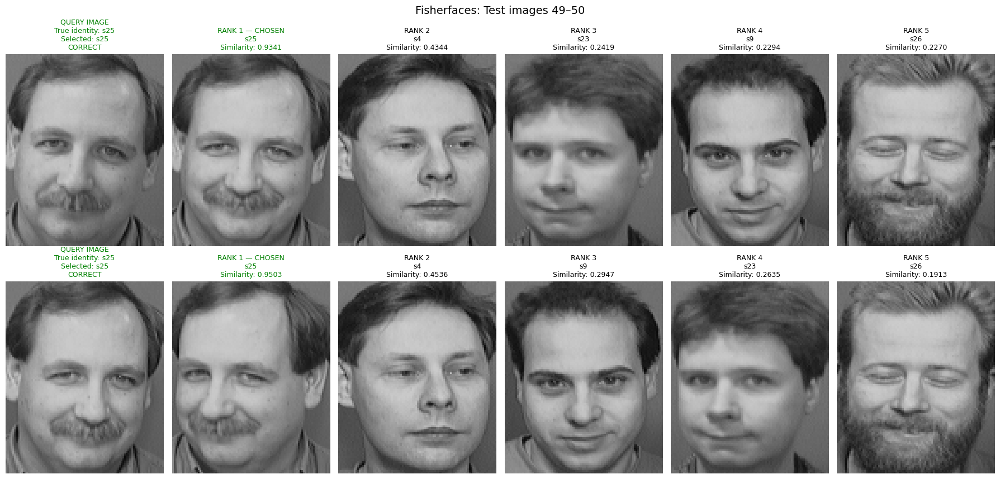

Test 51/76 | True: s26 | Selected: s26 | CORRECT | Top-1 similarity: 0.9259 | Top-5: s26, s28, s37, s25, s3
,Test 52/76 | True: s26 | Selected: s26 | CORRECT | Top-1 similarity: 0.9475 | Top-5: s26, s37, s28, s9, s12


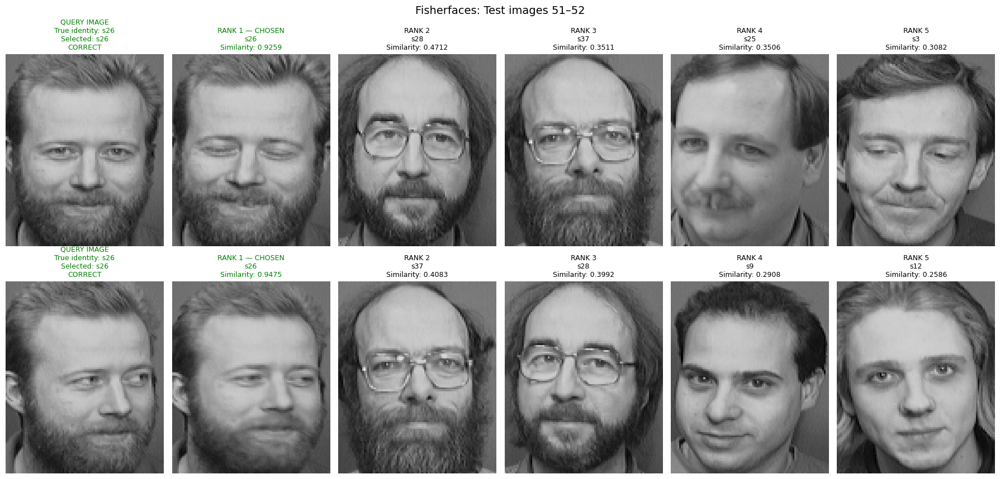

Test 53/76 | True: s27 | Selected: s27 | CORRECT | Top-1 similarity: 0.9482 | Top-5: s27, s2, s32, s37, s13
,Test 54/76 | True: s27 | Selected: s27 | CORRECT | Top-1 similarity: 0.9070 | Top-5: s27, s4, s14, s19, s2


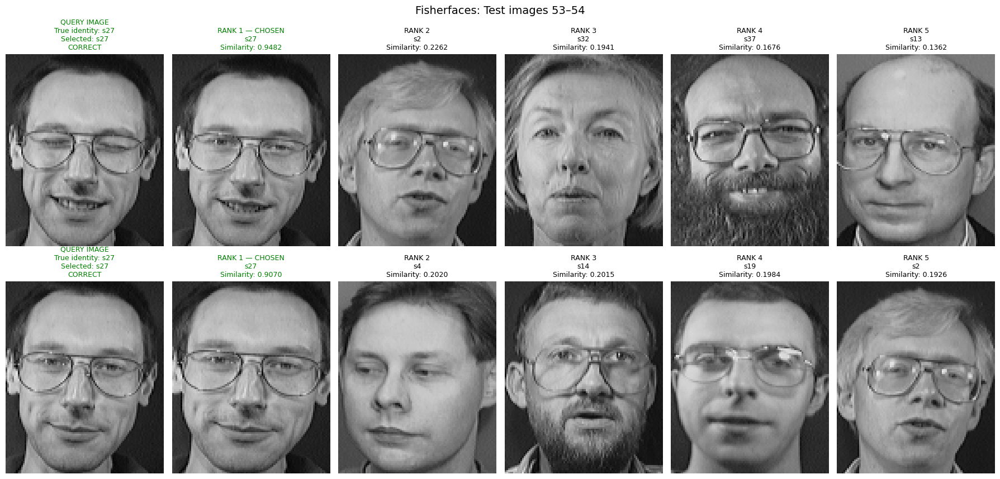

Test 55/76 | True: s28 | Selected: s28 | CORRECT | Top-1 similarity: 0.6664 | Top-5: s28, s37, s26, s12, s25
,Test 56/76 | True: s28 | Selected: s28 | CORRECT | Top-1 similarity: 0.5673 | Top-5: s28, s37, s13, s14, s26


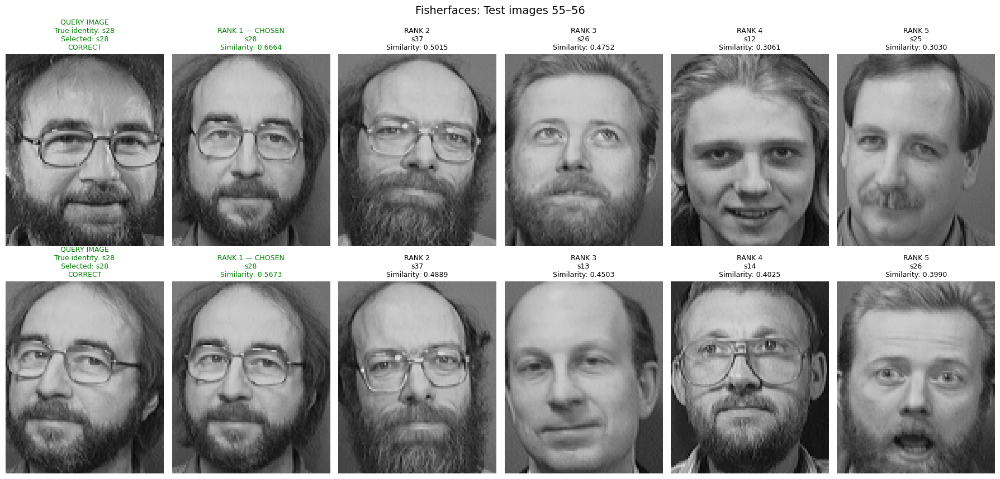

Test 57/76 | True: s29 | Selected: s29 | CORRECT | Top-1 similarity: 0.5387 | Top-5: s29, s33, s23, s38, s6
,Test 58/76 | True: s29 | Selected: s29 | CORRECT | Top-1 similarity: 0.9106 | Top-5: s29, s6, s20, s33, s7


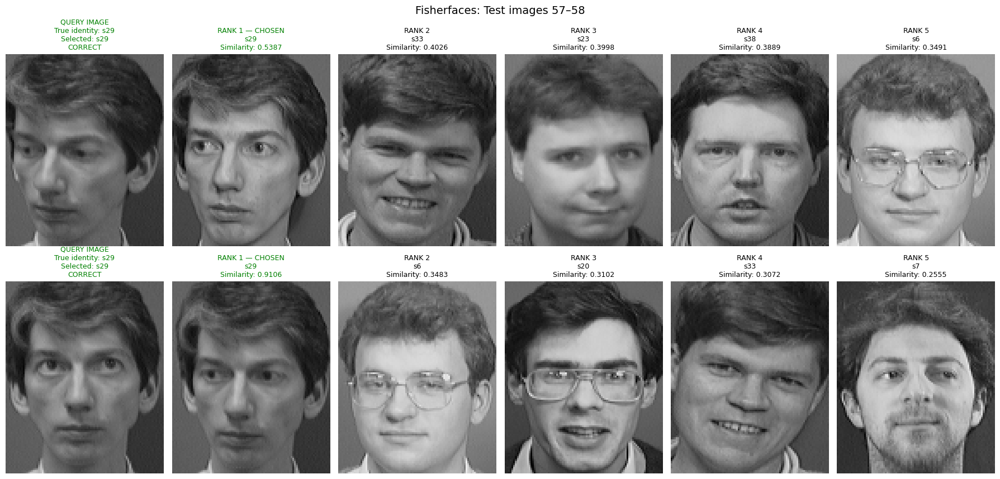

Test 59/76 | True: s30 | Selected: s30 | CORRECT | Top-1 similarity: 0.8793 | Top-5: s30, s6, s21, s33, s23
,Test 60/76 | True: s30 | Selected: s30 | CORRECT | Top-1 similarity: 0.9167 | Top-5: s30, s33, s6, s31, s38


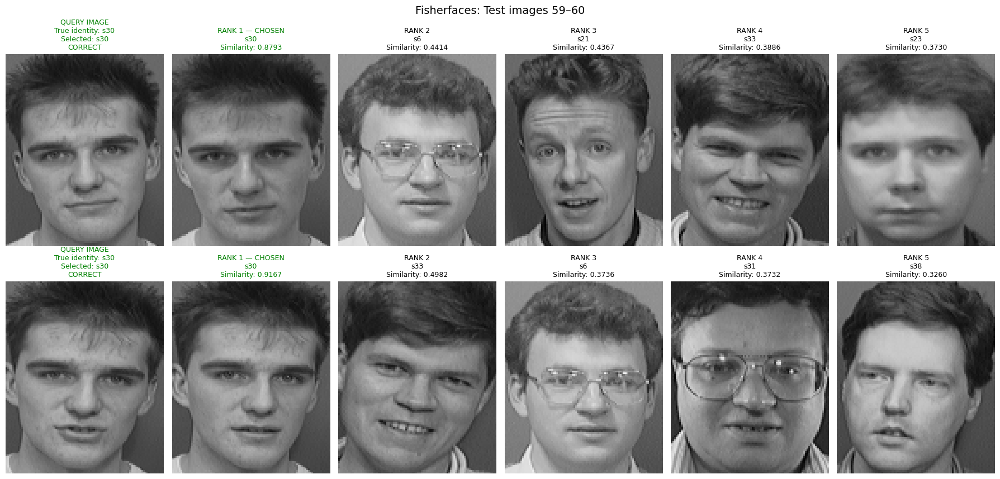

Test 61/76 | True: s31 | Selected: s31 | CORRECT | Top-1 similarity: 0.8348 | Top-5: s31, s9, s34, s30, s23
,Test 62/76 | True: s31 | Selected: s31 | CORRECT | Top-1 similarity: 0.8143 | Top-5: s31, s34, s21, s30, s9


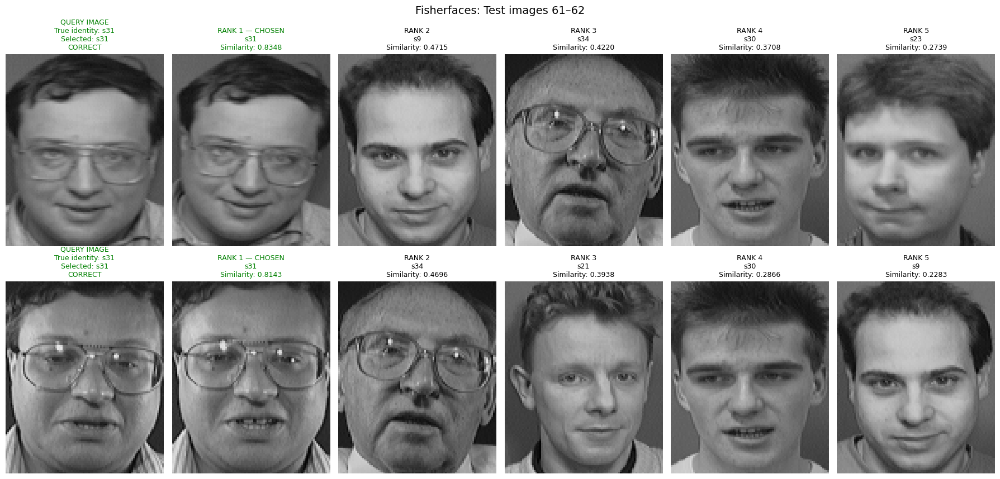

Test 63/76 | True: s32 | Selected: s32 | CORRECT | Top-1 similarity: 0.9187 | Top-5: s32, s2, s26, s19, s12
,Test 64/76 | True: s32 | Selected: s32 | CORRECT | Top-1 similarity: 0.9109 | Top-5: s32, s12, s2, s36, s26


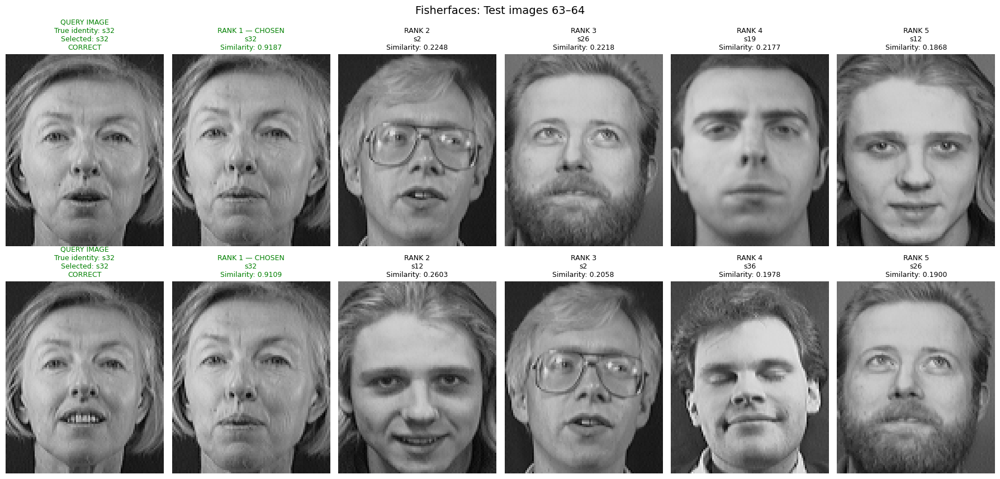

Test 65/76 | True: s33 | Selected: s33 | CORRECT | Top-1 similarity: 0.9230 | Top-5: s33, s20, s30, s6, s24
,Test 66/76 | True: s33 | Selected: s33 | CORRECT | Top-1 similarity: 0.9901 | Top-5: s33, s30, s20, s6, s24


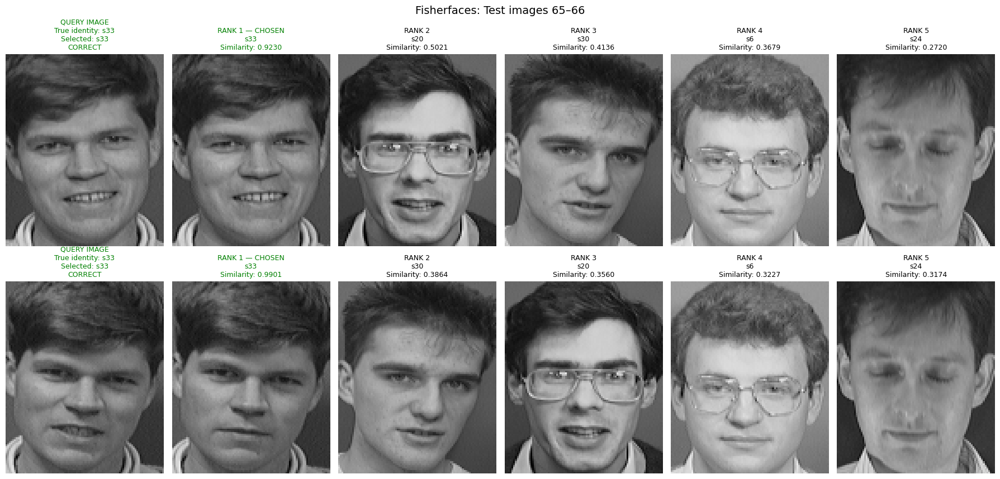

Test 67/76 | True: s34 | Selected: s34 | CORRECT | Top-1 similarity: 0.9165 | Top-5: s34, s31, s33, s22, s30
,Test 68/76 | True: s34 | Selected: s34 | CORRECT | Top-1 similarity: 0.9739 | Top-5: s34, s31, s33, s22, s30


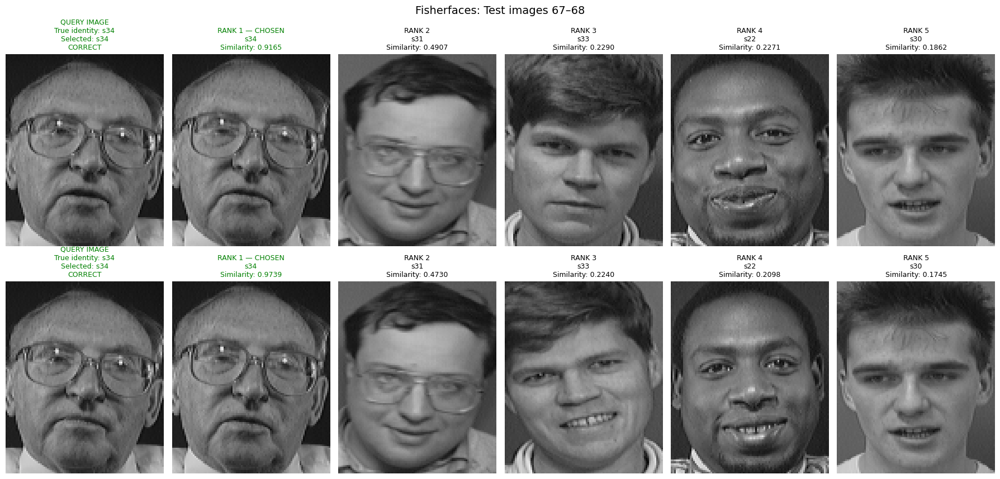

Test 69/76 | True: s35 | Selected: s35 | CORRECT | Top-1 similarity: 0.6421 | Top-5: s35, s34, s1, s8, s15
,Test 70/76 | True: s35 | Selected: s35 | CORRECT | Top-1 similarity: 0.5790 | Top-5: s35, s34, s1, s21, s25


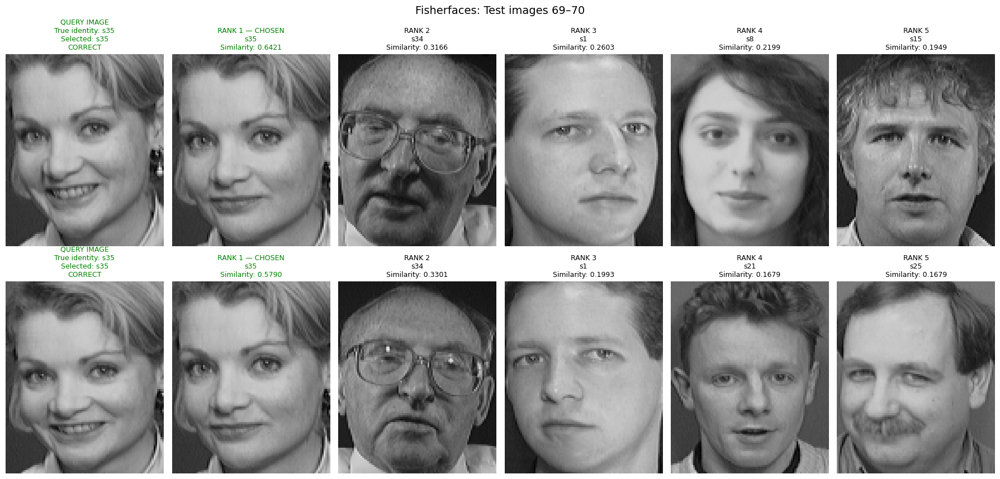

Test 71/76 | True: s36 | Selected: s36 | CORRECT | Top-1 similarity: 0.7598 | Top-5: s36, s1, s2, s17, s32
,Test 72/76 | True: s36 | Selected: s36 | CORRECT | Top-1 similarity: 0.6133 | Top-5: s36, s18, s16, s17, s1


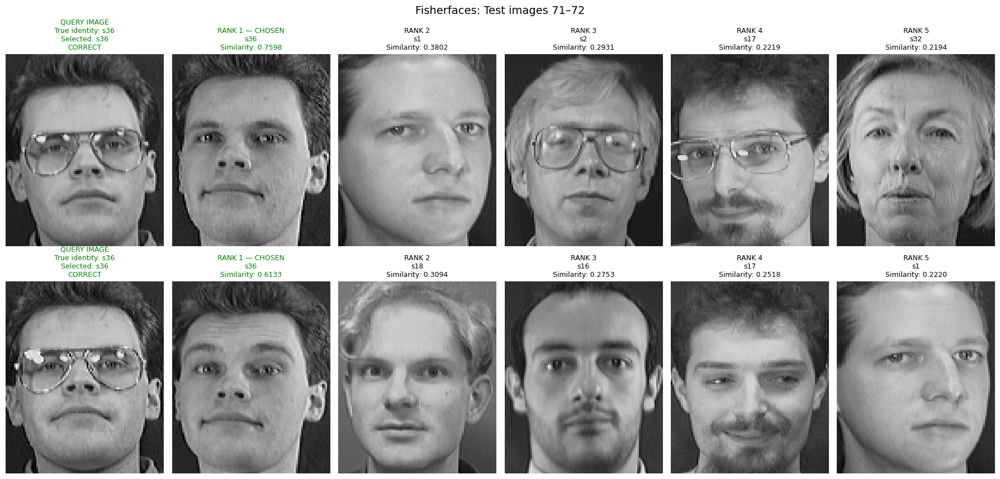

Test 73/76 | True: s37 | Selected: s37 | CORRECT | Top-1 similarity: 0.9308 | Top-5: s37, s28, s26, s13, s14
,Test 74/76 | True: s37 | Selected: s37 | CORRECT | Top-1 similarity: 0.8484 | Top-5: s37, s26, s28, s12, s3


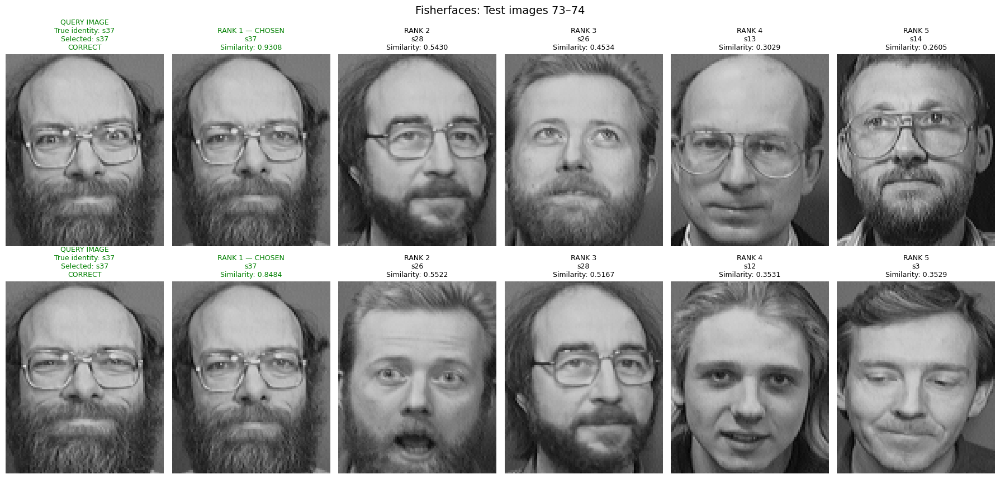

Test 75/76 | True: s38 | Selected: s38 | CORRECT | Top-1 similarity: 0.7403 | Top-5: s38, s23, s3, s29, s30
,Test 76/76 | True: s38 | Selected: s38 | CORRECT | Top-1 similarity: 0.8335 | Top-5: s38, s23, s6, s29, s30


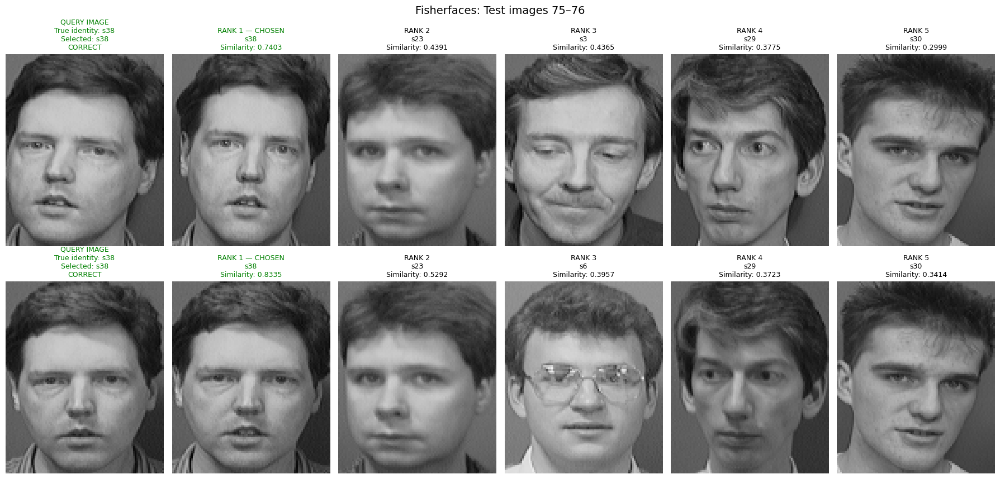


,
,===========================================================================
,FINAL SUMMARY: CLOSED-SET FACE RECOGNITION
,===========================================================================
,Identities: 38 (s1-s38)
,Training: images 1-8
,Testing: images 9-10
,Total training images: 304
,Total testing images: 76
,Method                 Correct     Wrong      Rank-1       Top-5
,----------------------------------------------------------------
,Eigenfaces                  72         4     94.74%     97.37%
,Fisherfaces                 74         2     97.37%    100.00%
,----------------------------------------------------------------
,Rank-1 = selected identity is exactly correct.
,Top-5 = true identity appears among the five highest-ranked identities.
,Rank 1 — CHOSEN identifies the actual algorithm prediction.


In [ ]:
# ===== TOP-5 VISUAL RESULTS FOR ALL 76 TEST IMAGES ==================
def show_all_top5(method_name, result, per_page=2):
    gallery = result["_gal"]
    query_features = result["_Qk"]
    people = gallery["people"]
    gallery_features = gallery["feat"]
    gallery_labels = gallery["labels"]
    total = len(TEST_ITEMS)
    print(f"\n{'=' * 75}")
    print(f"{method_name}: TOP-5 RESULTS FOR ALL {total} TEST IMAGES")
    print(f"{'=' * 75}")
    # Similarity of every query against every gallery image.
    all_scores = query_features @ gallery_features.T
    for start in range(0, total, per_page):
        selected = range(start, min(start + per_page, total))
        fig, axes = plt.subplots(len(selected), 6,figsize=(18, 4.5 * len(selected)),squeeze=False)

        for ax in axes.ravel():
            ax.axis("off")

        for row, query_index in enumerate(selected):
            true_person = TEST_LABELS[query_index]
            query_item = TEST_ITEMS[query_index]
            # Score each identity using its best matching gallery image.
            identity_scores = []
            identity_gallery_indices = []

            for person in people:
                indices = np.flatnonzero(gallery_labels == person)
                scores = all_scores[query_index, indices]
                best_local = np.argmax(scores)
                identity_scores.append(scores[best_local])
                identity_gallery_indices.append(indices[best_local])
            identity_scores = np.asarray(identity_scores)
            identity_gallery_indices = np.asarray(identity_gallery_indices)
            # Rank identities from highest to lowest similarity.
            order = np.argsort(-identity_scores)
            top5 = order[:min(5, len(order))]
            chosen_person = people[top5[0]]
            is_correct = chosen_person == true_person
            # Column 1: actual query image.
            axes[row, 0].imshow(item_gray(query_item),cmap="gray", vmin=0, vmax=255)
            axes[row, 0].set_title(
                f"QUERY IMAGE\n"
                f"True identity: {true_person}\n"
                f"Selected: {chosen_person}\n"
                f"{'CORRECT' if is_correct else 'WRONG'}",
                fontsize=9,
                color="green" if is_correct else "red"
            )
            # Columns 2-6: top-five gallery matches.
            for rank, identity_index in enumerate(top5):
                col = rank + 1
                person = people[identity_index]
                gallery_index = int(identity_gallery_indices[identity_index])
                score = identity_scores[identity_index]
                axes[row, col].imshow(
                    item_gray(gallery["items"][gallery_index]),cmap="gray", vmin=0, vmax=255)
                if rank == 0:
                    title = (
                        f"RANK 1 — CHOSEN\n"
                        f"{person}\n"
                        f"Similarity: {score:.4f}"
                    )
                    title_color = "green" if is_correct else "red"
                else:
                    title = (
                        f"RANK {rank + 1}\n"
                        f"{person}\n"
                        f"Similarity: {score:.4f}"
                    )
                    title_color = "black"

                axes[row, col].set_title(
                    title,
                    fontsize=9,
                    color=title_color
                )
                # Highlight the selected identity.
                for spine in axes[row, col].spines.values():
                    spine.set_visible(True)
                    spine.set_linewidth(3 if rank == 0 else 1)
                    spine.set_edgecolor(
                        "green" if rank == 0 and is_correct
                        else "red" if rank == 0
                        else "gray"
                    )

            print(
                f"Test {query_index + 1:02d}/76 | "
                f"True: {true_person} | "
                f"Selected: {chosen_person} | "
                f"{'CORRECT' if is_correct else 'WRONG'} | "
                f"Top-1 similarity: {identity_scores[top5[0]]:.4f} | "
                f"Top-5: {', '.join(str(people[i]) for i in top5)}"
            )
        fig.suptitle(f"{method_name}: Test images "f"{start + 1}–{min(start + per_page, total)}",fontsize=14)

        plt.tight_layout()
        plt.show()
        plt.close(fig)


#DISPLAY ALL 76 TEST IMAGES FOR BOTH METHODS
show_all_top5("Eigenfaces", RESULTS["Eigenfaces"])
show_all_top5("Fisherfaces", RESULTS["Fisherfaces"])
#FINAL SUMMARY TABLE
print("\n")
print("=" * 75)
print("FINAL SUMMARY: CLOSED-SET FACE RECOGNITION")
print("=" * 75)
print("Identities: 38 (s1-s38)")
print("Training: images 1-8")
print("Testing: images 9-10")
print("Total training images:", len(GAL_ITEMS))
print("Total testing images:", len(TEST_ITEMS))
print(    f"{'Method':<20}"f"{'Correct':>10}"f"{'Wrong':>10}"f"{'Rank-1':>12}"f"{'Top-5':>12}")
print("-" * 64)
for name, result in RESULTS.items():
    wrong = result["n_test"] - result["n_correct"]
    print(f"{name:<20}"f"{result['n_correct']:>10}"f"{wrong:>10}"f"{result['top1']:>11.2%}"f"{result['top5']:>11.2%}")
print("-" * 64)
print("Rank-1 = selected identity is exactly correct.")
print("Top-5 = true identity appears among the five highest-ranked identities.")
print("Rank 1 — CHOSEN identifies the actual algorithm prediction.")